In [ ]:
"""
========================================================================
NIFTY FINANCIAL SERVICES INDEX - EVENT STUDY ANALYSIS
Investigates macroeconomic & policy announcement impacts via
Abnormal Returns, CAR, and Volatility analysis.
Period: 31-Mar-2025 to 31-Mar-2026
========================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Matplotlib global style ────────────────────────────────────────────
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'figure.facecolor': '#F8F9FA',
    'axes.facecolor': '#F8F9FA',
    'axes.titlesize': 12,
    'axes.labelsize': 10,
})


from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/My Drive/NIFTY/NIFTY_FINANCIAL_SERVICES.csv'

Mounted at /content/drive


In [ ]:
import matplotlib as mpl

# 1. Force white backgrounds globally
mpl.rcParams['figure.facecolor'] = 'white'
mpl.rcParams['axes.facecolor'] = 'white'
mpl.rcParams['savefig.facecolor'] = 'white'
mpl.rcParams['savefig.edgecolor'] = 'white'

# 2. Set text colors to black (for contrast)
mpl.rcParams['text.color'] = 'black'
mpl.rcParams['axes.labelcolor'] = 'black'
mpl.rcParams['xtick.color'] = 'black'
mpl.rcParams['ytick.color'] = 'black'

# 3. Configure seaborn for clean academic style
sns.set_style("whitegrid")  # White background with light grid
sns.set_context("paper")     # or "notebook" for larger figures

# 4. Optional: Set default figure size and DPI
mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['savefig.dpi'] = 300

print("✅ Global plotting configuration set (white backgrounds enabled)")

✅ Global plotting configuration set (white backgrounds enabled)


In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 1.  LOAD & CLEAN DATA
# ══════════════════════════════════════════════════════════════════════
print("=" * 65)
print(" NIFTY FINANCIAL SERVICES — EVENT STUDY ANALYSIS")
print("=" * 65)

df = pd.read_csv(
    file_path,
    encoding='utf-8-sig'
)

# Strip whitespace from column names
df.columns = df.columns.str.strip()

# Parse dates  (format: DD-MMM-YYYY e.g. 25-MAR-2026)
df['Date'] = pd.to_datetime(df['Date'], format='%d-%b-%Y')
df = df.sort_values('Date').reset_index(drop=True)

print(f"\n Data loaded: {len(df)} trading days")
print(f"   Period : {df['Date'].min().date()}  →  {df['Date'].max().date()}")
print(f"   Close range: ₹{df['Close'].min():,.2f} – ₹{df['Close'].max():,.2f}")


 NIFTY FINANCIAL SERVICES — EVENT STUDY ANALYSIS

 Data loaded: 247 trading days
   Period : 2025-04-01  →  2026-03-30
   Close range: ₹23,521.80 – ₹28,463.25


In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 2.  DAILY RETURNS
# ══════════════════════════════════════════════════════════════════════
df['Return'] = df['Close'].pct_change() * 100   # in %

# ══════════════════════════════════════════════════════════════════════
# 3.  DEFINE KEY EVENTS
# ══════════════════════════════════════════════════════════════════════
events = {
    'Union Budget 2025\n(Feb 1, 2025)':     pd.Timestamp('2025-02-01'),
    'RBI MPC – Apr 2025\n(Apr 9, 2025)':    pd.Timestamp('2025-04-09'),
    'RBI MPC – Jun 2025\n(Jun 6, 2025)':    pd.Timestamp('2025-06-06'),
    'RBI MPC – Aug 2025\n(Aug 6, 2025)':    pd.Timestamp('2025-08-06'),
    'RBI MPC – Oct 2025\n(Oct 1, 2025)':    pd.Timestamp('2025-10-01'),
    'RBI MPC – Dec 2025\n(Dec 5, 2025)':    pd.Timestamp('2025-12-05'),
    'Union Budget 2026\n(Feb 1, 2026)':     pd.Timestamp('2026-02-01'),
    'RBI MPC – Feb 2026\n(Feb 6, 2026)':    pd.Timestamp('2026-02-06'),
}

# ── Helper: get correct event day (first trading day on or after announcement) ──
def nearest_trading_day(announcement_date, trading_days):
    """
    Return the correct event day for an announcement.

    - If announcement_date is a trading day → return that day (assumes intraday).
    - Else → return the next trading day (first trading day on or after).

    This fixes the weekend problem (e.g., Saturday → Monday, not Friday).
    """
    if announcement_date in trading_days.values:
        return announcement_date
    else:
        # Find first trading day >= announcement_date
        future_days = trading_days[trading_days >= announcement_date]
        if len(future_days) == 0:
            raise ValueError(f"No trading day on or after {announcement_date}")
        return future_days.iloc[0]

trading_days = df['Date']

# Example usage (to test):
# for name, date in events.items():
#     event_day = get_event_day(date, trading_days)
#     print(f"{name} -> Official: {date.date()} -> Event day: {event_day.date()}")

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 4.  EVENT-WINDOW ANALYSIS  (−5 to +5 days)
# ══════════════════════════════════════════════════════════════════════
EVENT_WINDOW = 5       # days either side
ESTIMATION_WINDOW = 30 # days before event window for normal-return baseline

def get_event_analysis(event_name, event_date, df, event_window=5, est_window=30):
    """
    Returns a dict with AR, CAR, vol_pre, vol_post for one event.
    """
    t0_date = nearest_trading_day(event_date, df['Date'])
    t0_idx  = df[df['Date'] == t0_date].index[0]

    # Indices for estimation window (no overlap with event window)
    est_start = max(0, t0_idx - event_window - est_window)
    est_end   = t0_idx - event_window - 1

    if est_end - est_start < 5:
        return None   # not enough data

    est_returns   = df.loc[est_start:est_end, 'Return'].dropna()
    normal_return = est_returns.mean()
    vol_pre       = est_returns.std()

    # Event window indices
    ev_start = max(0, t0_idx - event_window)
    ev_end   = min(len(df) - 1, t0_idx + event_window)
    ev_df    = df.loc[ev_start:ev_end].copy()
    ev_df['day'] = range(-(t0_idx - ev_start), (ev_end - t0_idx) + 1)

    ev_df['AR']  = ev_df['Return'] - normal_return
    ev_df['CAR'] = ev_df['AR'].cumsum()

    vol_post = df.loc[t0_idx: t0_idx + event_window, 'Return'].dropna().std()

    return {
        'name':        event_name,
        'event_date':  t0_date,
        'ev_df':       ev_df,
        'normal_ret':  normal_return,
        'vol_pre':     vol_pre,
        'vol_post':    vol_post,
        'ar_event':    ev_df[ev_df['day'] == 0]['AR'].values[0] if 0 in ev_df['day'].values else np.nan,
        'car_total':   ev_df['CAR'].iloc[-1],
    }

results = {}
for name, date in events.items():
    res = get_event_analysis(name, date, df)
    if res:
        results[name] = res
        short = name.split('\n')[0]
        print(f"\n📌 {short}")
        print(f"   Event date  : {res['event_date'].date()}")
        print(f"   Normal ret  : {res['normal_ret']:+.4f}%")
        print(f"   AR on event : {res['ar_event']:+.4f}%")
        print(f"   CAR (window): {res['car_total']:+.4f}%")
        print(f"   Vol pre/post: {res['vol_pre']:.4f}% / {res['vol_post']:.4f}%")


📌 RBI MPC – Jun 2025
   Event date  : 2025-06-06
   Normal ret  : +0.1606%
   AR on event : +1.5893%
   CAR (window): -2.2778%
   Vol pre/post: 1.1332% / 1.0103%

📌 RBI MPC – Aug 2025
   Event date  : 2025-08-06
   Normal ret  : +0.0336%
   AR on event : -0.0425%
   CAR (window): -2.0989%
   Vol pre/post: 0.6968% / 0.7499%

📌 RBI MPC – Oct 2025
   Event date  : 2025-10-01
   Normal ret  : +0.0515%
   AR on event : +1.3324%
   CAR (window): +0.0782%
   Vol pre/post: 0.6201% / 0.6694%

📌 RBI MPC – Dec 2025
   Event date  : 2025-12-05
   Normal ret  : +0.1379%
   AR on event : +0.8415%
   CAR (window): -2.4840%
   Vol pre/post: 0.6058% / 0.7007%

📌 Union Budget 2026
   Event date  : 2026-02-01
   Normal ret  : -0.0473%
   AR on event : -2.2642%
   CAR (window): +3.0151%
   Vol pre/post: 0.5445% / 1.7978%

📌 RBI MPC – Feb 2026
   Event date  : 2026-02-06
   Normal ret  : -0.0048%
   AR on event : +0.4300%
   CAR (window): +3.0176%
   Vol pre/post: 0.6251% / 0.6952%


In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 5.  ROLLING VOLATILITY (30-day)
# ══════════════════════════════════════════════════════════════════════
df['Vol30'] = df['Return'].rolling(30).std()

In [ ]:
output_dir = '/content/drive/My Drive/NIFTY/'

In [ ]:
# ── NEW: Statistical Testing & Seaborn Imports ────────────────────────
from scipy import stats
import seaborn as sns

# Seaborn theme — matches our existing dark-spine style
sns.set_theme(
    style="whitegrid",
    palette="deep",
    font="DejaVu Sans",
    rc={
        "axes.spines.top":   False,
        "axes.spines.right": False,
        "figure.facecolor":  "#F8F9FA",
        "axes.facecolor":    "#F8F9FA",
        "grid.alpha":        0.35,
        "grid.linestyle":    "--",
    }
)

print("✅ scipy.stats and seaborn loaded")


✅ scipy.stats and seaborn loaded


In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 6A.  PARAMETRIC T-TEST FOR STATISTICAL SIGNIFICANCE
# ══════════════════════════════════════════════════════════════════════
#
# We run TWO complementary t-tests per event:
#
# TEST 1 — One-Sample t-test on the AR series over the event window
#   H₀ : mean(AR) = 0  (event had no effect on returns)
#   H₁ : mean(AR) ≠ 0  (event generated abnormal returns)
#   Sample: all 11 daily ARs in the event window (−5 to +5)
#
# TEST 2 — Standardised Event-Day AR (Patell / BMP style)
#   t = AR₀ / (σ_est / √n_est)
#   Tests whether the single event-day AR is extreme
#   relative to the estimation-window standard deviation
#
# Significance levels:
#   *** p < 0.01  |  ** p < 0.05  |  * p < 0.10  |  n.s. = not significant
# ──────────────────────────────────────────────────────────────────────

def run_ttest(res, df, event_window=5, est_window=30):
    """
    Compute both t-tests for a single event result dict.
    Returns a dict of all statistical outputs.
    """
    ev_df     = res['ev_df']
    ar_series = ev_df['AR'].dropna()

    # ── Estimation window stats (already computed in get_event_analysis) ──
    t0_date   = res['event_date']
    t0_idx    = df[df['Date'] == t0_date].index[0]
    est_start = max(0, t0_idx - event_window - est_window)
    est_end   = t0_idx - event_window - 1
    est_ret   = df.loc[est_start:est_end, 'Return'].dropna()
    sigma_est = est_ret.std()
    n_est     = len(est_ret)

    # ── TEST 1: One-sample t-test (mean AR = 0?) ──────────────────────
    t1_stat, t1_pval = stats.ttest_1samp(ar_series, popmean=0)
    t1_df            = len(ar_series) - 1
    ci95             = stats.t.interval(0.95, df=t1_df,
                                        loc=ar_series.mean(),
                                        scale=stats.sem(ar_series))

    # ── TEST 2: Standardised event-day AR ─────────────────────────────
    ar0    = res['ar_event']
    t2_stat = ar0 / sigma_est if sigma_est > 0 else float('nan')
    # Two-tailed p-value using t-distribution with n_est-1 df
    t2_pval = 2 * stats.t.sf(abs(t2_stat), df=n_est - 1) if not np.isnan(t2_stat) else float('nan')

    def sig_stars(p):
        if np.isnan(p): return 'n/a'
        if p < 0.01:    return '***'
        if p < 0.05:    return '**'
        if p < 0.10:    return '*'
        return 'n.s.'

    return {
        'event':        res['name'].split('\n')[0],
        'event_date':   res['event_date'].date(),
        'ar0':          ar0,
        'car_total':    res['car_total'],
        'mean_ar_win':  ar_series.mean(),
        # Test 1
        't1_stat':      t1_stat,
        't1_pval':      t1_pval,
        't1_sig':       sig_stars(t1_pval),
        'ci95_lo':      ci95[0],
        'ci95_hi':      ci95[1],
        # Test 2
        't2_stat':      t2_stat,
        't2_pval':      t2_pval,
        't2_sig':       sig_stars(t2_pval),
        'sigma_est':    sigma_est,
        'n_est':        n_est,
    }

# ── Run for all events ─────────────────────────────────────────────────
ttest_results = {}
for name, res in results.items():
    if res is None:
        continue
    stats_out = run_ttest(res, df)
    ttest_results[name] = stats_out

ttest_df = pd.DataFrame(ttest_results.values())

# ── Print formatted table ──────────────────────────────────────────────
print("=" * 95)
print(f"{'EVENT':<28} {'AR₀%':>6} {'CAR%':>7} | TEST 1 (Window)          | TEST 2 (Event Day)")
print(f"{'':28} {'':>6} {'':>7} | {'t-stat':>7} {'p-val':>7} {'Sig':>5} {'95% CI':>14} | {'t-stat':>7} {'p-val':>7} {'Sig':>5}")
print("-" * 95)
for _, row in ttest_df.iterrows():
    ci_str = f"[{row['ci95_lo']:+.3f},{row['ci95_hi']:+.3f}]"
    print(
        f"{row['event']:<28} {row['ar0']:>+6.3f} {row['car_total']:>+7.3f} | "
        f"{row['t1_stat']:>7.3f} {row['t1_pval']:>7.4f} {row['t1_sig']:>5} {ci_str:>14} | "
        f"{row['t2_stat']:>7.3f} {row['t2_pval']:>7.4f} {row['t2_sig']:>5}"
    )
print("=" * 95)
print()
print("INTERPRETATION:")
print("  Test 1  →  H₀: mean AR over the 11-day event window = 0")
print("  Test 2  →  H₀: event-day AR₀ is not different from estimation-window noise")
print("  Both tests use a two-tailed 95% confidence level as standard.")
print()
print("  ⚠️  NOTE: With only 11 event-window observations (Test 1) and ~25 estimation")
print("  window days (Test 2), statistical power is limited by design.")
print("  n.s. results do NOT mean no effect — they reflect small sample size.")
print("  This is precisely why researchers aggregate across multiple events / years.")

EVENT                          AR₀%    CAR% | TEST 1 (Window)          | TEST 2 (Event Day)
                                            |  t-stat   p-val   Sig         95% CI |  t-stat   p-val   Sig
-----------------------------------------------------------------------------------------------
RBI MPC – Jun 2025           +1.589  -2.278 |  -0.895  0.3916  n.s. [-0.722,+0.308] |   1.402  0.1714  n.s.
RBI MPC – Aug 2025           -0.042  -2.099 |  -1.132  0.2841  n.s. [-0.566,+0.185] |  -0.061  0.9518  n.s.
RBI MPC – Oct 2025           +1.332  +0.078 |   0.033  0.9743  n.s. [-0.473,+0.487] |   2.149  0.0401    **
RBI MPC – Dec 2025           +0.842  -2.484 |  -1.293  0.2251  n.s. [-0.615,+0.163] |   1.389  0.1754  n.s.
Union Budget 2026            -2.264  +3.015 |   0.639  0.5374  n.s. [-0.682,+1.230] |  -4.159  0.0003   ***
RBI MPC – Feb 2026           +0.430  +3.018 |   0.668  0.5193  n.s. [-0.641,+1.190] |   0.688  0.4969  n.s.

INTERPRETATION:
  Test 1  →  H₀: mean AR over the 11-day

✅ Fig 1 (Seaborn) saved → /content/drive/My Drive/NIFTY/fig1_sns_overview.png


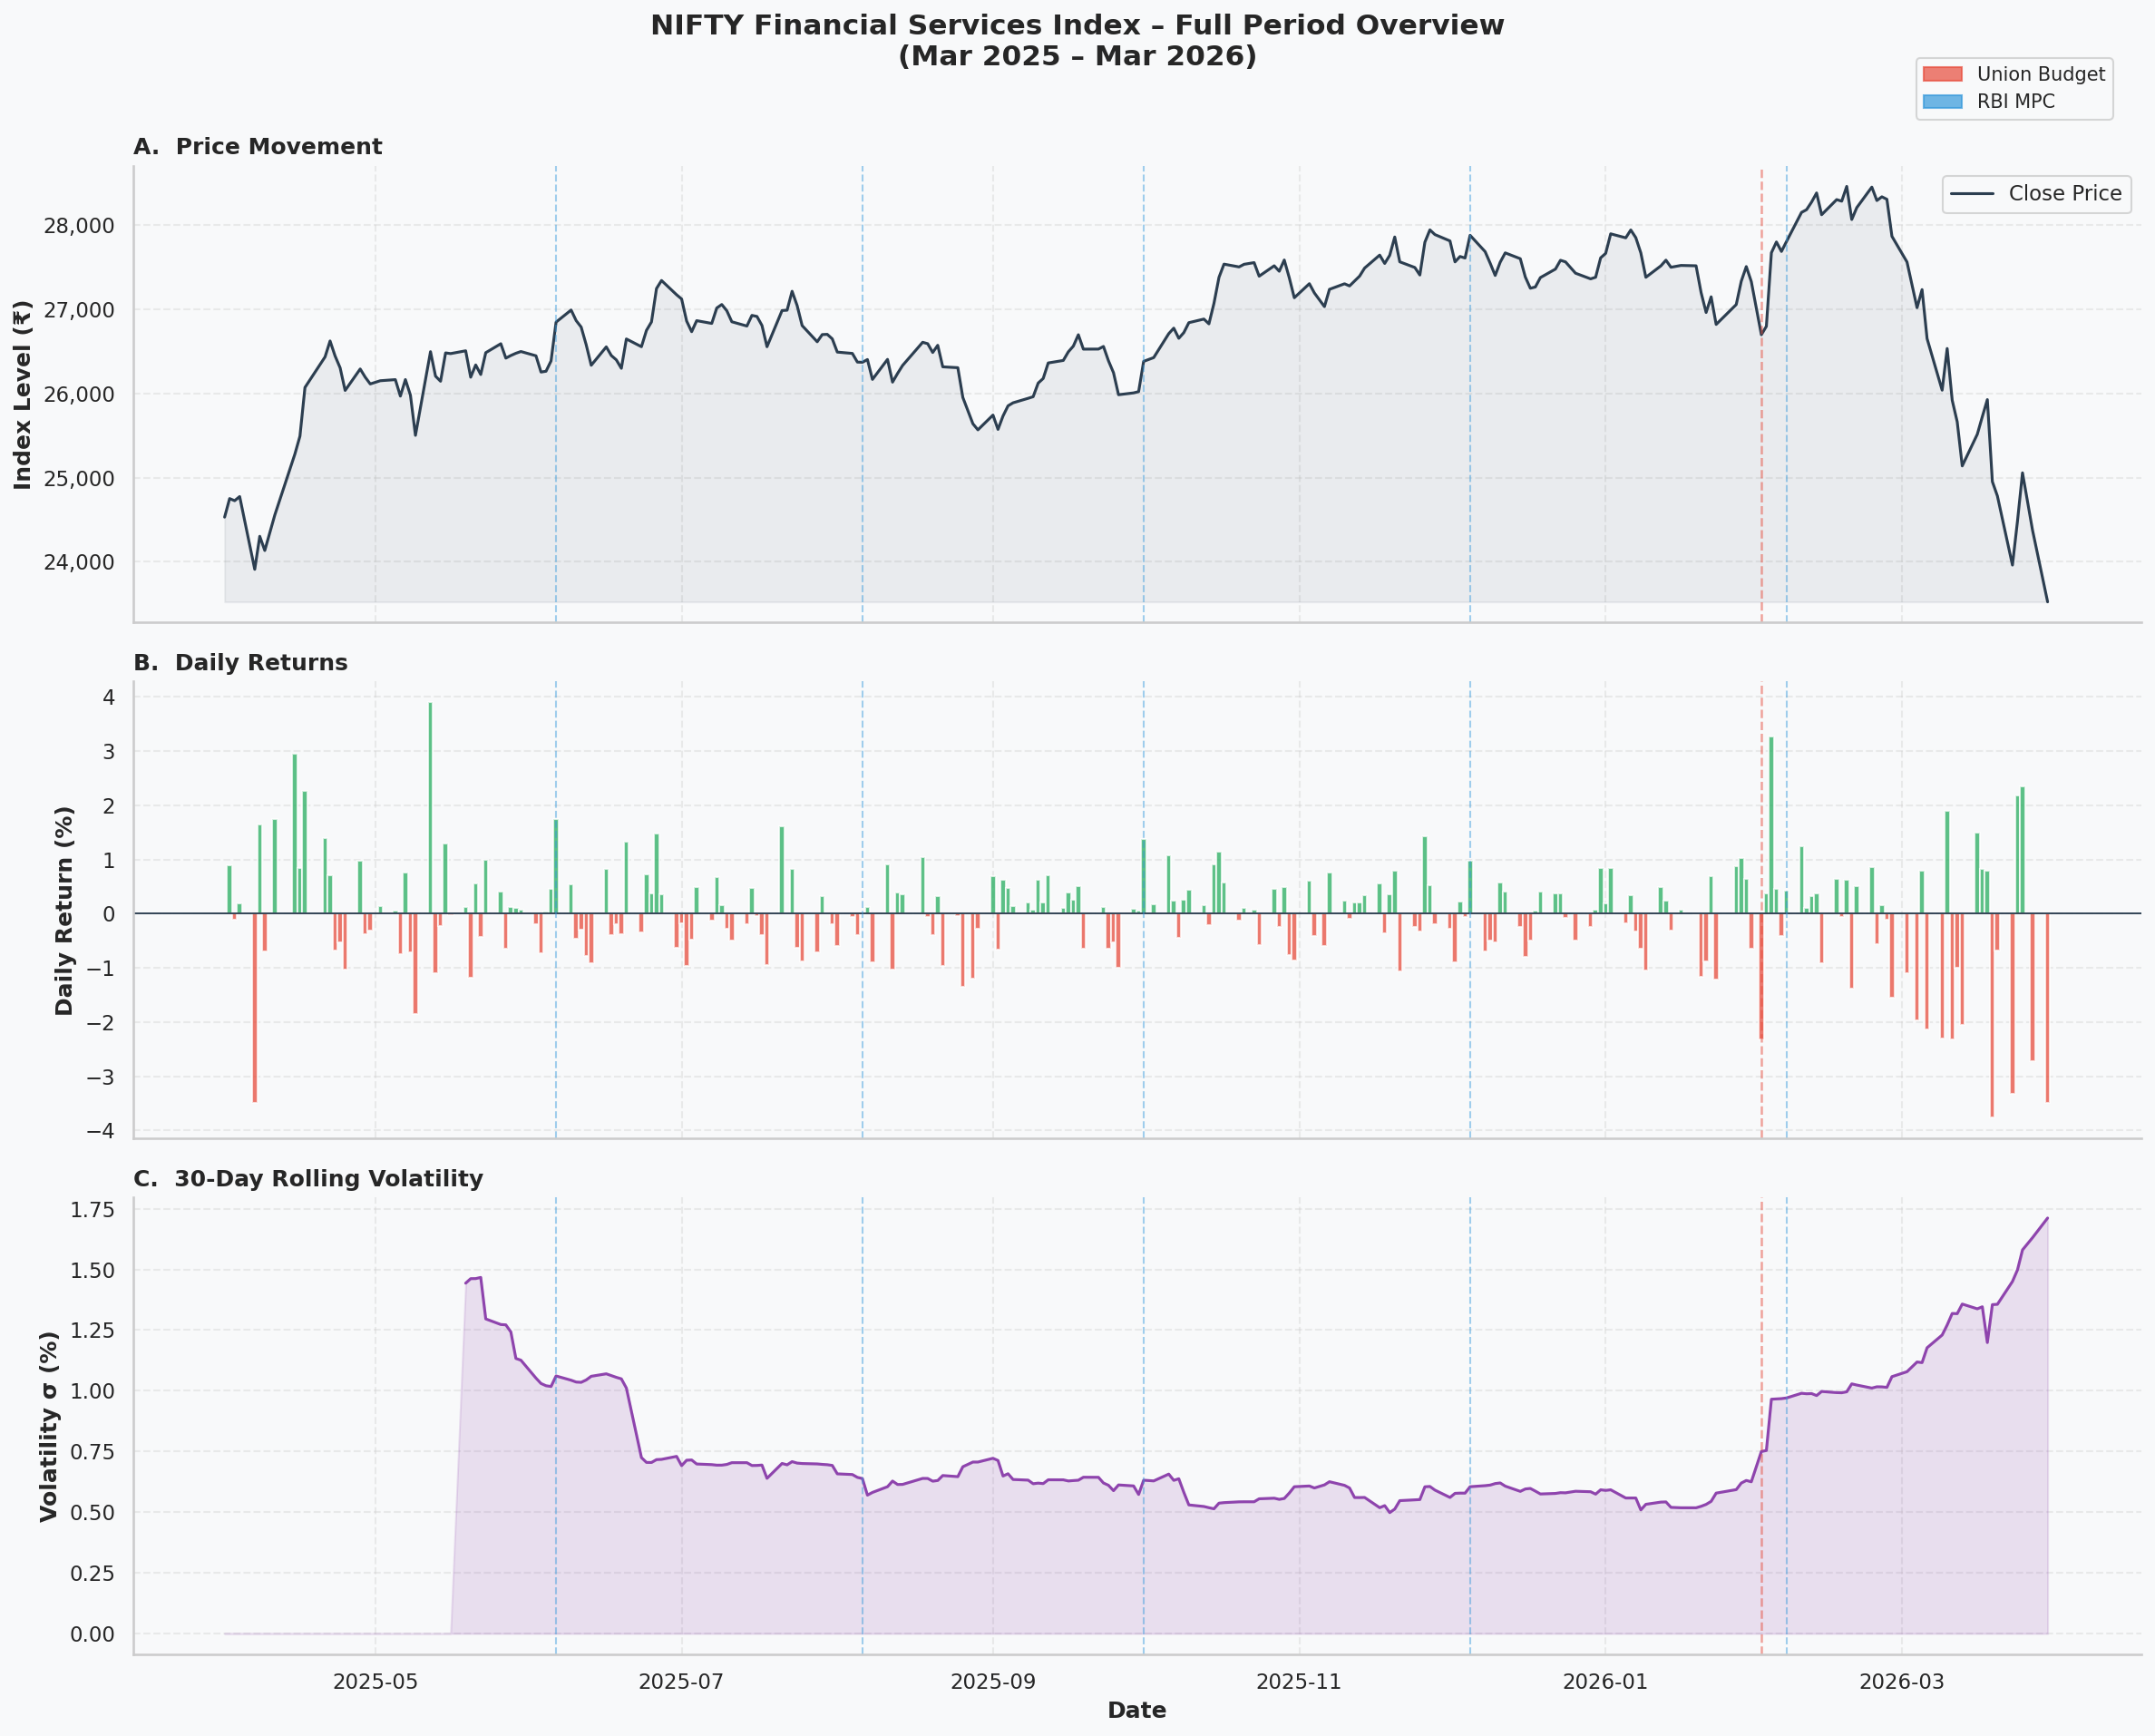

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 7A. [SEABORN] FIGURE 1 — PRICE / RETURN / VOLATILITY OVERVIEW
# ══════════════════════════════════════════════════════════════════════

fig1s, axes1s = plt.subplots(3, 1, figsize=(16, 13), sharex=True,
                              facecolor='#F8F9FA')
fig1s.suptitle('NIFTY Financial Services Index – Full Period Overview\n(Mar 2025 – Mar 2026)',
               fontsize=15, fontweight='bold', y=0.98)

ax1s, ax2s, ax3s = axes1s
budget_dates = [r['event_date'] for n, r in results.items() if 'Budget' in n]
rbi_dates    = [r['event_date'] for n, r in results.items() if 'RBI'    in n]

# ── Panel A: Price ─────────────────────────────────────────────────────
sns.lineplot(data=df, x='Date', y='Close', ax=ax1s,
             color='#2C3E50', linewidth=1.5, label='Close Price')
ax1s.fill_between(df['Date'], df['Close'], df['Close'].min(),
                  alpha=0.07, color='#2C3E50')
ax1s.set_ylabel('Index Level (₹)', fontweight='bold')
ax1s.set_title('A.  Price Movement', fontweight='bold', loc='left')
ax1s.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax1s.set_xlabel('')

# ── Panel B: Daily Returns ─────────────────────────────────────────────
ret_df = df[['Date','Return']].copy().dropna()
ret_df['Color'] = ret_df['Return'].apply(lambda r: '#27AE60' if r >= 0 else '#E74C3C')
ax2s.bar(ret_df['Date'], ret_df['Return'], color=ret_df['Color'], alpha=0.75, width=1)
ax2s.axhline(0, color='#2C3E50', linewidth=0.9, linestyle='-')
ax2s.set_ylabel('Daily Return (%)', fontweight='bold')
ax2s.set_title('B.  Daily Returns', fontweight='bold', loc='left')
ax2s.set_xlabel('')

# ── Panel C: 30-day Rolling Volatility ────────────────────────────────
sns.lineplot(data=df, x='Date', y='Vol30', ax=ax3s,
             color='#8E44AD', linewidth=1.5)
ax3s.fill_between(df['Date'], df['Vol30'].fillna(0), alpha=0.15, color='#8E44AD')
ax3s.set_ylabel('Volatility σ (%)', fontweight='bold')
ax3s.set_title('C.  30-Day Rolling Volatility', fontweight='bold', loc='left')
ax3s.set_xlabel('Date', fontweight='bold')

# ── Event vlines on all panels ─────────────────────────────────────────
for ax in [ax1s, ax2s, ax3s]:
    for d in budget_dates: ax.axvline(d, color='#E74C3C', alpha=0.5, linestyle='--', linewidth=1.2)
    for d in rbi_dates:    ax.axvline(d, color='#3498DB', alpha=0.45, linestyle='--', linewidth=1.0)

budget_patch = mpatches.Patch(color='#E74C3C', alpha=0.7, label='Union Budget')
rbi_patch    = mpatches.Patch(color='#3498DB', alpha=0.7, label='RBI MPC')
fig1s.legend(handles=[budget_patch, rbi_patch], loc='upper right',
             frameon=True, fontsize=10, bbox_to_anchor=(0.98, 0.96))

plt.tight_layout(rect=[0, 0, 1, 0.97])
fig1s.savefig(f'{output_dir}fig1_sns_overview.png', dpi=150, bbox_inches='tight')
print(f"✅ Fig 1 (Seaborn) saved → {output_dir}fig1_sns_overview.png")


✅ Fig 2 (Seaborn) saved → /content/drive/My Drive/NIFTY/fig2_sns_ar_heatmap.png


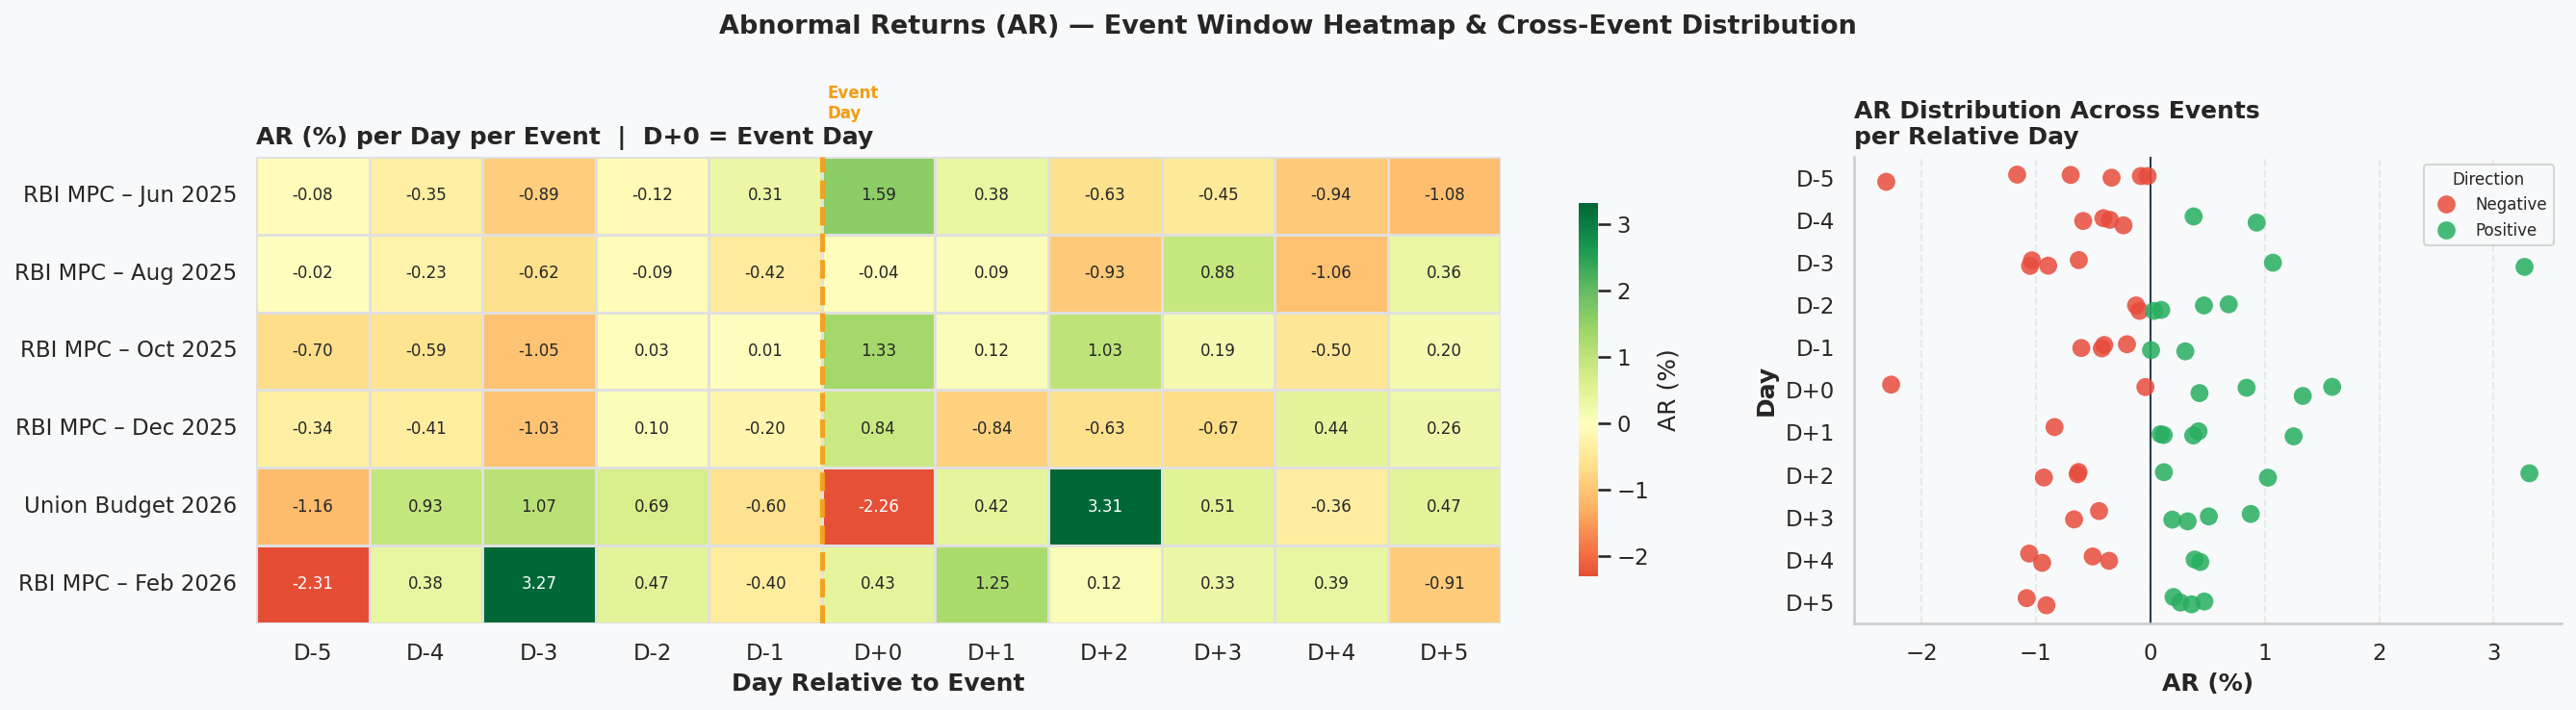

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 7B. [SEABORN] FIGURE 2 — ABNORMAL RETURNS HEATMAP + PER-EVENT BARS
# ══════════════════════════════════════════════════════════════════════

# Build a pivot table: rows = events, cols = days −5…+5
ar_matrix = {}
for name, res in results.items():
    ev = res['ev_df'].set_index('day')['AR']
    ar_matrix[name.split('\n')[0]] = ev

ar_pivot = pd.DataFrame(ar_matrix).T
ar_pivot.columns = [f"D{int(c):+d}" for c in ar_pivot.columns]

fig2s, (ax_heat, ax_strip) = plt.subplots(
    1, 2, figsize=(18, 5),
    gridspec_kw={'width_ratios': [2.2, 1]},
    facecolor='#F8F9FA'
)
fig2s.suptitle('Abnormal Returns (AR) — Event Window Heatmap & Cross-Event Distribution',
               fontsize=13, fontweight='bold')

# ── Left: Diverging Heatmap ─────────────────────────────────────────────
sns.heatmap(
    ar_pivot,
    ax=ax_heat,
    cmap='RdYlGn',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    linecolor='#E0E0E0',
    cbar_kws={'label': 'AR (%)', 'shrink': 0.8},
    annot_kws={'size': 8},
)
ax_heat.set_title('AR (%) per Day per Event  |  D+0 = Event Day', fontweight='bold', loc='left')
ax_heat.set_xlabel('Day Relative to Event', fontweight='bold')
ax_heat.set_ylabel('')
ax_heat.axvline(5.0, color='#F39C12', linewidth=2.5, linestyle='--', alpha=0.9)
ax_heat.text(5.05, -0.5, 'Event\nDay', color='#F39C12', fontsize=8, fontweight='bold')

# ── Right: Strip plot — distribution of AR values per day ──────────────
ar_long = ar_pivot.reset_index().melt(id_vars='index', var_name='Day', value_name='AR')
ar_long.columns = ['Event', 'Day', 'AR']
day_order = [f"D{i:+d}" for i in range(-5, 6)]
ar_long['color'] = ar_long['AR'].apply(lambda v: 'Positive' if v >= 0 else 'Negative')

sns.stripplot(
    data=ar_long,
    x='AR',
    y='Day',
    hue='color',
    order=day_order,
    palette={'Positive': '#27AE60', 'Negative': '#E74C3C'},
    ax=ax_strip,
    size=9,
    alpha=0.85,
    jitter=0.15,
)
ax_strip.axvline(0, color='#2C3E50', linewidth=1)
ax_strip.set_title('AR Distribution Across Events\nper Relative Day', fontweight='bold', loc='left')
ax_strip.set_xlabel('AR (%)', fontweight='bold')
ax_strip.set_ylabel('Day', fontweight='bold')
ax_strip.legend(title='Direction', fontsize=8, title_fontsize=8)

plt.tight_layout()
fig2s.savefig(f'{output_dir}fig2_sns_ar_heatmap.png', dpi=150, bbox_inches='tight')
print(f"✅ Fig 2 (Seaborn) saved → {output_dir}fig2_sns_ar_heatmap.png")


✅ Fig 3 (Seaborn) saved → /content/drive/My Drive/NIFTY/fig3_sns_car.png


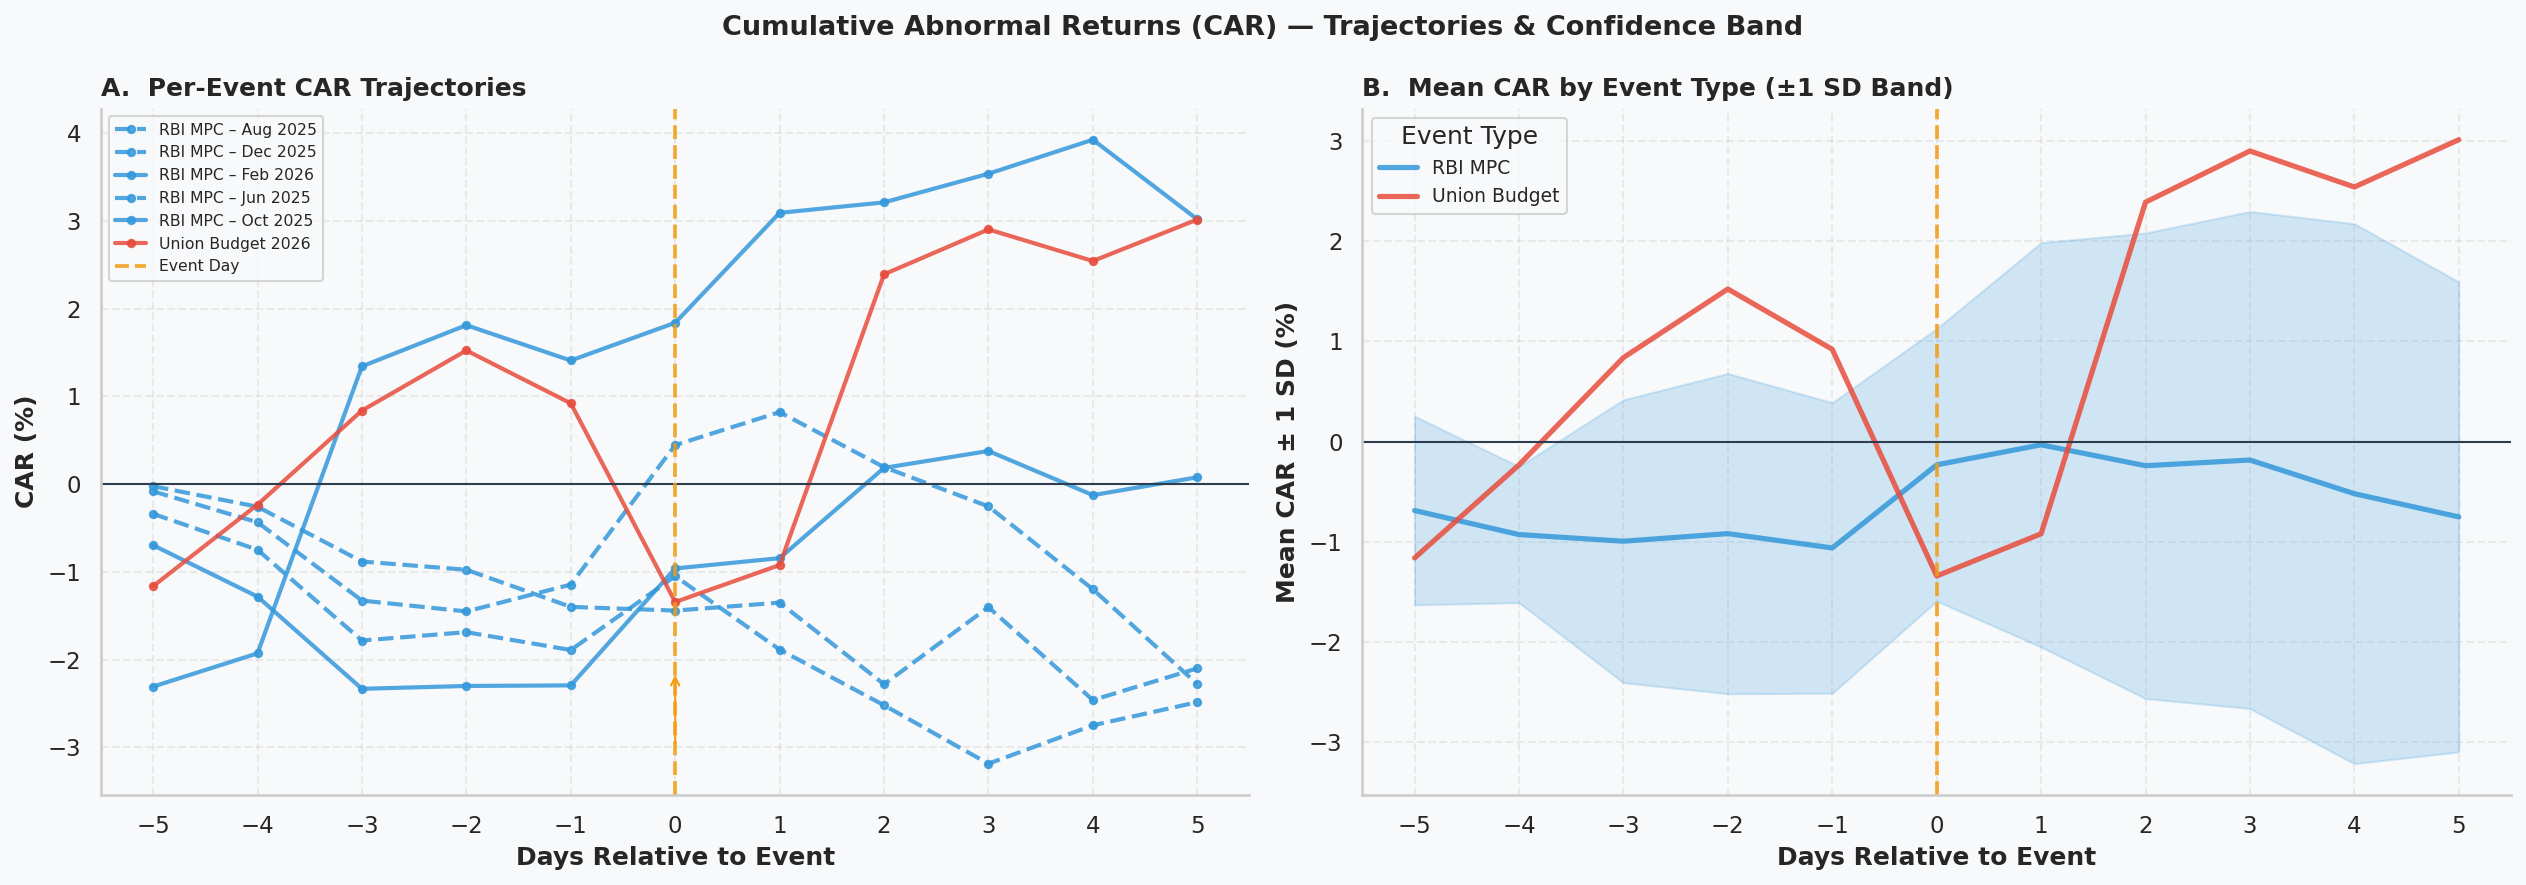

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 7C. [SEABORN] FIGURE 3 — CAR TRAJECTORIES WITH CONFIDENCE BAND
# ══════════════════════════════════════════════════════════════════════

# Build long-form CAR dataframe
car_rows = []
for name, res in results.items():
    ev   = res['ev_df']
    etype = 'Union Budget' if 'Budget' in name else 'RBI MPC'
    short = name.split('\n')[0]
    for _, row in ev.iterrows():
        car_rows.append({
            'Event':      short,
            'Type':       etype,
            'Day':        int(row['day']),
            'CAR':        row['CAR'],
            'AR':         row['AR'],
        })

car_long = pd.DataFrame(car_rows)

fig3s, axes3s = plt.subplots(1, 2, figsize=(17, 6), facecolor='#F8F9FA')
fig3s.suptitle('Cumulative Abnormal Returns (CAR) — Trajectories & Confidence Band',
               fontsize=13, fontweight='bold')

# ── Left: Individual CAR lines coloured by event type ─────────────────
palette_type = {'Union Budget': '#E74C3C', 'RBI MPC': '#3498DB'}
for name, grp in car_long.groupby('Event'):
    etype = grp['Type'].iloc[0]
    col   = palette_type[etype]
    ls    = '-' if grp['CAR'].iloc[-1] > 0 else '--'
    axes3s[0].plot(grp['Day'], grp['CAR'], color=col, linewidth=2,
                   linestyle=ls, marker='o', markersize=3.5, alpha=0.85, label=name)

axes3s[0].axhline(0, color='#2C3E50', linewidth=1)
axes3s[0].axvline(0, color='#F39C12', linewidth=1.8, linestyle='--', alpha=0.85, label='Event Day')
axes3s[0].set_xlabel('Days Relative to Event', fontweight='bold')
axes3s[0].set_ylabel('CAR (%)', fontweight='bold')
axes3s[0].set_title('A.  Per-Event CAR Trajectories', fontweight='bold', loc='left')
axes3s[0].set_xticks(range(-5, 6))
axes3s[0].legend(fontsize=7.5, ncol=1, loc='upper left')
axes3s[0].add_patch(mpatches.FancyArrowPatch(
    (0, axes3s[0].get_ylim()[0]*0.85), (0, axes3s[0].get_ylim()[0]*0.6),
    color='#F39C12', arrowstyle='->', mutation_scale=10
))

# ── Right: Mean CAR ± 1 SD band across all events (seaborn lineplot) ──
sns.lineplot(
    data=car_long,
    x='Day',
    y='CAR',
    hue='Type',
    palette=palette_type,
    ax=axes3s[1],
    linewidth=2.5,
    errorbar='sd',        # shaded ±1 SD band
    err_style='band',
    alpha=0.85,
    markers=True,
    dashes=False,
)
axes3s[1].axhline(0, color='#2C3E50', linewidth=1)
axes3s[1].axvline(0, color='#F39C12', linewidth=1.8, linestyle='--', alpha=0.85)
axes3s[1].set_xlabel('Days Relative to Event', fontweight='bold')
axes3s[1].set_ylabel('Mean CAR ± 1 SD (%)', fontweight='bold')
axes3s[1].set_title('B.  Mean CAR by Event Type (±1 SD Band)', fontweight='bold', loc='left')
axes3s[1].set_xticks(range(-5, 6))
axes3s[1].legend(title='Event Type', fontsize=9)

plt.tight_layout()
fig3s.savefig(f'{output_dir}fig3_sns_car.png', dpi=150, bbox_inches='tight')
print(f"✅ Fig 3 (Seaborn) saved → {output_dir}fig3_sns_car.png")


✅ Fig 4 (Seaborn) saved → /content/drive/My Drive/NIFTY/fig4_sns_ttest.png


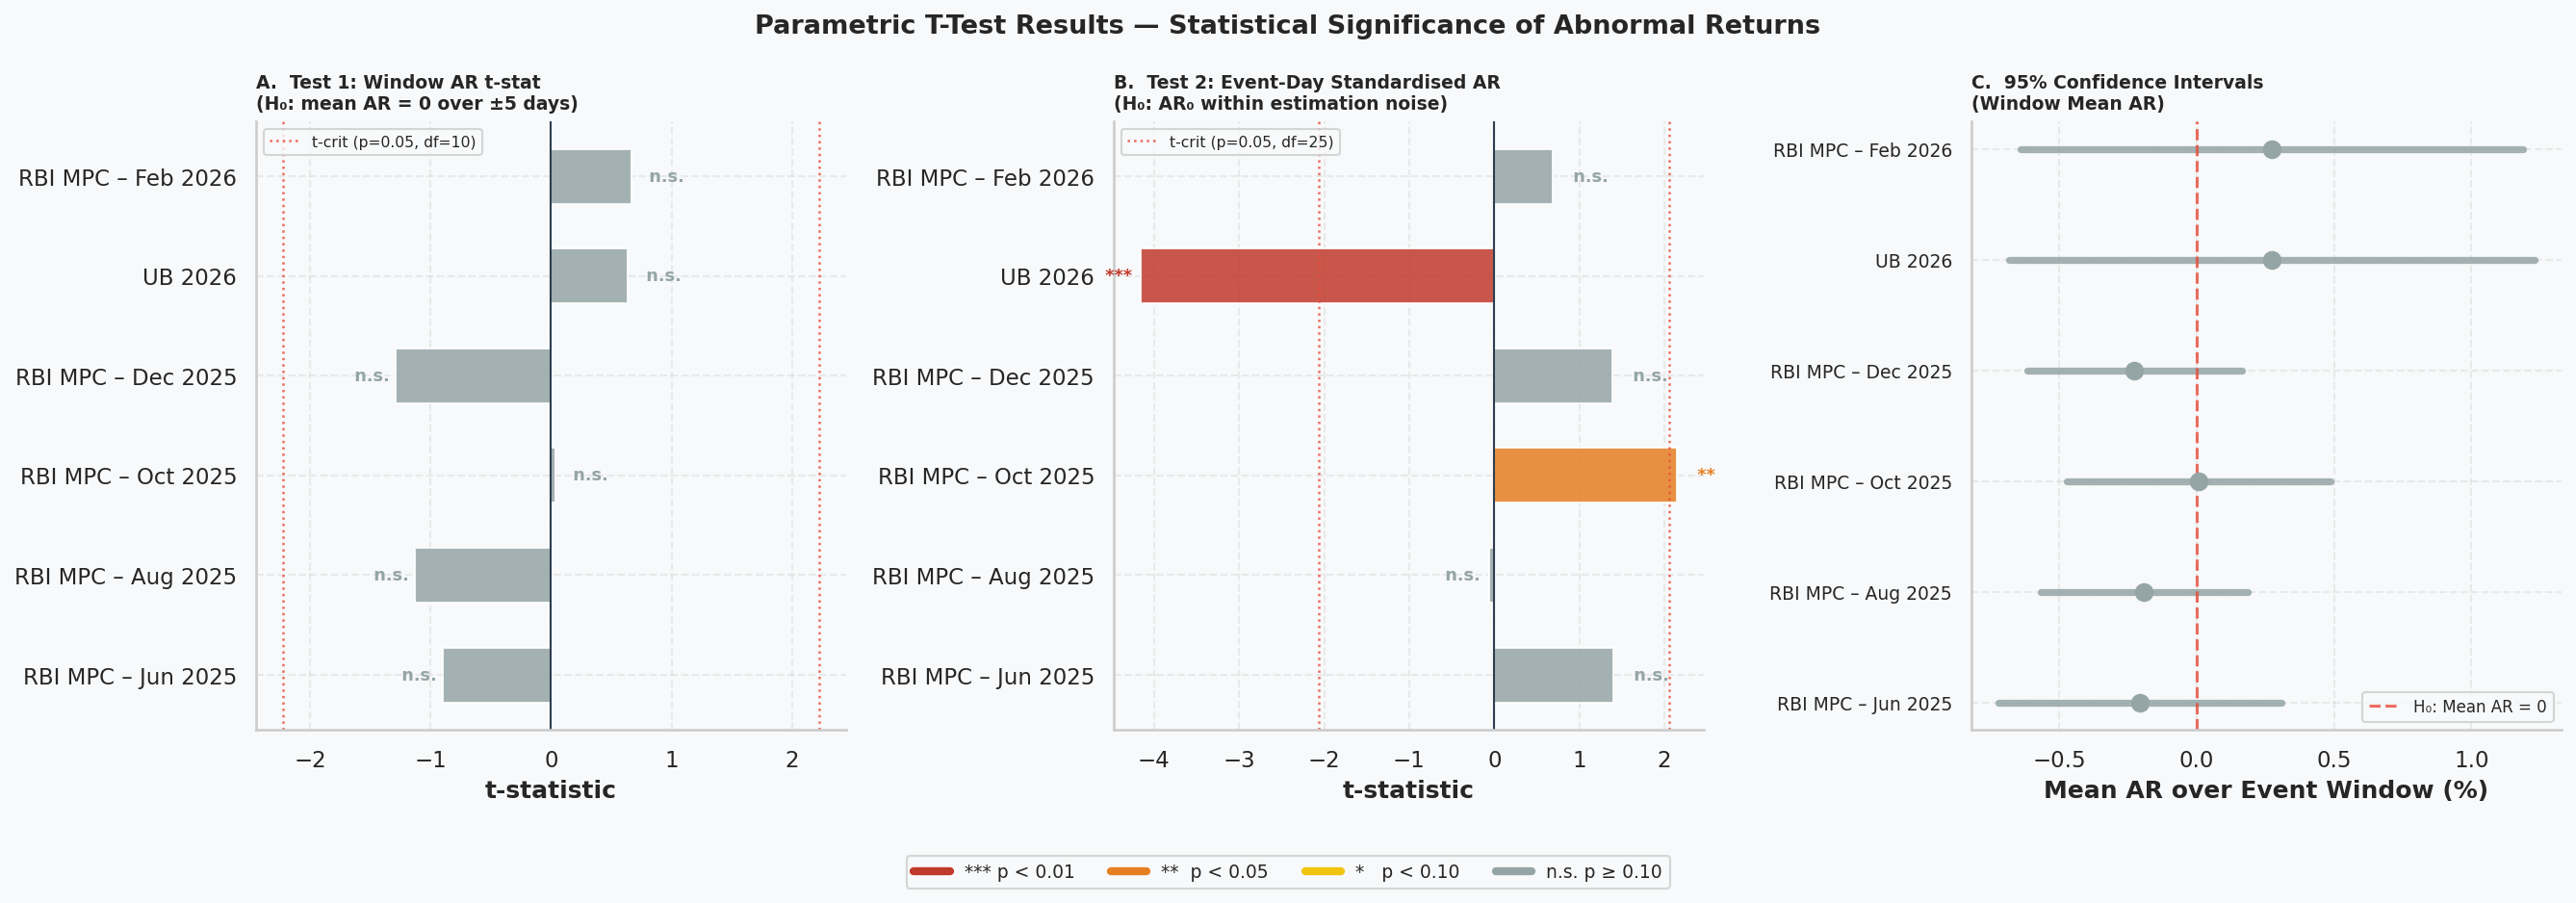

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 7D. [SEABORN] FIGURE 4 — T-TEST RESULTS VISUALISATION
# ══════════════════════════════════════════════════════════════════════

fig4s, axes4s = plt.subplots(1, 3, figsize=(18, 6), facecolor='#F8F9FA')
fig4s.suptitle('Parametric T-Test Results — Statistical Significance of Abnormal Returns',
               fontsize=13, fontweight='bold')

# Colour coding by significance
def sig_color(p):
    if p < 0.01:  return '#C0392B'   # red   ***
    if p < 0.05:  return '#E67E22'   # orange **
    if p < 0.10:  return '#F1C40F'   # yellow *
    return '#95A5A6'                  # grey  n.s.

ttest_df_plot = ttest_df.copy()
ttest_df_plot['short'] = ttest_df_plot['event'].str.replace('Union Budget', 'UB')
ttest_df_plot['t1_color'] = ttest_df_plot['t1_pval'].apply(sig_color)
ttest_df_plot['t2_color'] = ttest_df_plot['t2_pval'].apply(sig_color)

# ── Panel A: Test 1 t-statistics with p-value colour ──────────────────
bars_t1 = axes4s[0].barh(
    ttest_df_plot['short'],
    ttest_df_plot['t1_stat'],
    color=ttest_df_plot['t1_color'],
    alpha=0.85, edgecolor='white', height=0.55
)
axes4s[0].axvline(0, color='#2C3E50', linewidth=1)
axes4s[0].axvline( 2.228, color='#E74C3C', linewidth=1.2, linestyle=':', alpha=0.8, label='t-crit (p=0.05, df=10)')
axes4s[0].axvline(-2.228, color='#E74C3C', linewidth=1.2, linestyle=':', alpha=0.8)
for bar, (_, row) in zip(bars_t1, ttest_df_plot.iterrows()):
    x = row['t1_stat']
    axes4s[0].text(x + (0.05 if x >= 0 else -0.05), bar.get_y() + bar.get_height()/2,
                   f"  {row['t1_sig']}", va='center', fontsize=8.5, fontweight='bold',
                   color=row['t1_color'], ha='left' if x >= 0 else 'right')
axes4s[0].set_xlabel('t-statistic', fontweight='bold')
axes4s[0].set_title('A.  Test 1: Window AR t-stat\n(H₀: mean AR = 0 over ±5 days)', fontweight='bold', loc='left', fontsize=9)
axes4s[0].legend(fontsize=7.5)

# ── Panel B: Test 2 t-statistics ──────────────────────────────────────
bars_t2 = axes4s[1].barh(
    ttest_df_plot['short'],
    ttest_df_plot['t2_stat'],
    color=ttest_df_plot['t2_color'],
    alpha=0.85, edgecolor='white', height=0.55
)
axes4s[1].axvline(0, color='#2C3E50', linewidth=1)
axes4s[1].axvline( 2.060, color='#E74C3C', linewidth=1.2, linestyle=':', alpha=0.8, label='t-crit (p=0.05, df=25)')
axes4s[1].axvline(-2.060, color='#E74C3C', linewidth=1.2, linestyle=':', alpha=0.8)
for bar, (_, row) in zip(bars_t2, ttest_df_plot.iterrows()):
    x = row['t2_stat']
    axes4s[1].text(x + (0.1 if x >= 0 else -0.1), bar.get_y() + bar.get_height()/2,
                   f"  {row['t2_sig']}", va='center', fontsize=8.5, fontweight='bold',
                   color=row['t2_color'], ha='left' if x >= 0 else 'right')
axes4s[1].set_xlabel('t-statistic', fontweight='bold')
axes4s[1].set_title('B.  Test 2: Event-Day Standardised AR\n(H₀: AR₀ within estimation noise)', fontweight='bold', loc='left', fontsize=9)
axes4s[1].legend(fontsize=7.5)

# ── Panel C: 95% CI on mean AR (window) ───────────────────────────────
for i, (_, row) in enumerate(ttest_df_plot.iterrows()):
    col = sig_color(row['t1_pval'])
    axes4s[2].plot([row['ci95_lo'], row['ci95_hi']], [i, i],
                   color=col, linewidth=3.5, solid_capstyle='round', alpha=0.85)
    axes4s[2].scatter(row['mean_ar_win'], i, color=col, s=70, zorder=5)

axes4s[2].axvline(0, color='#E74C3C', linewidth=1.5, linestyle='--', alpha=0.8, label='H₀: Mean AR = 0')
axes4s[2].set_yticks(range(len(ttest_df_plot)))
axes4s[2].set_yticklabels(ttest_df_plot['short'], fontsize=9)
axes4s[2].set_xlabel('Mean AR over Event Window (%)', fontweight='bold')
axes4s[2].set_title('C.  95% Confidence Intervals\n(Window Mean AR)', fontweight='bold', loc='left', fontsize=9)
axes4s[2].legend(fontsize=8)

# Significance legend
from matplotlib.lines import Line2D
leg_handles = [
    Line2D([0],[0], color='#C0392B', lw=4, label='*** p < 0.01'),
    Line2D([0],[0], color='#E67E22', lw=4, label='**  p < 0.05'),
    Line2D([0],[0], color='#F1C40F', lw=4, label='*   p < 0.10'),
    Line2D([0],[0], color='#95A5A6', lw=4, label='n.s. p ≥ 0.10'),
]
fig4s.legend(handles=leg_handles, loc='lower center', ncol=4,
             fontsize=9, frameon=True, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout(rect=[0, 0.04, 1, 1])
fig4s.savefig(f'{output_dir}fig4_sns_ttest.png', dpi=150, bbox_inches='tight')
print(f"✅ Fig 4 (Seaborn) saved → {output_dir}fig4_sns_ttest.png")


✅ Fig 5 (Seaborn) saved → /content/drive/My Drive/NIFTY/fig5_sns_summary.png


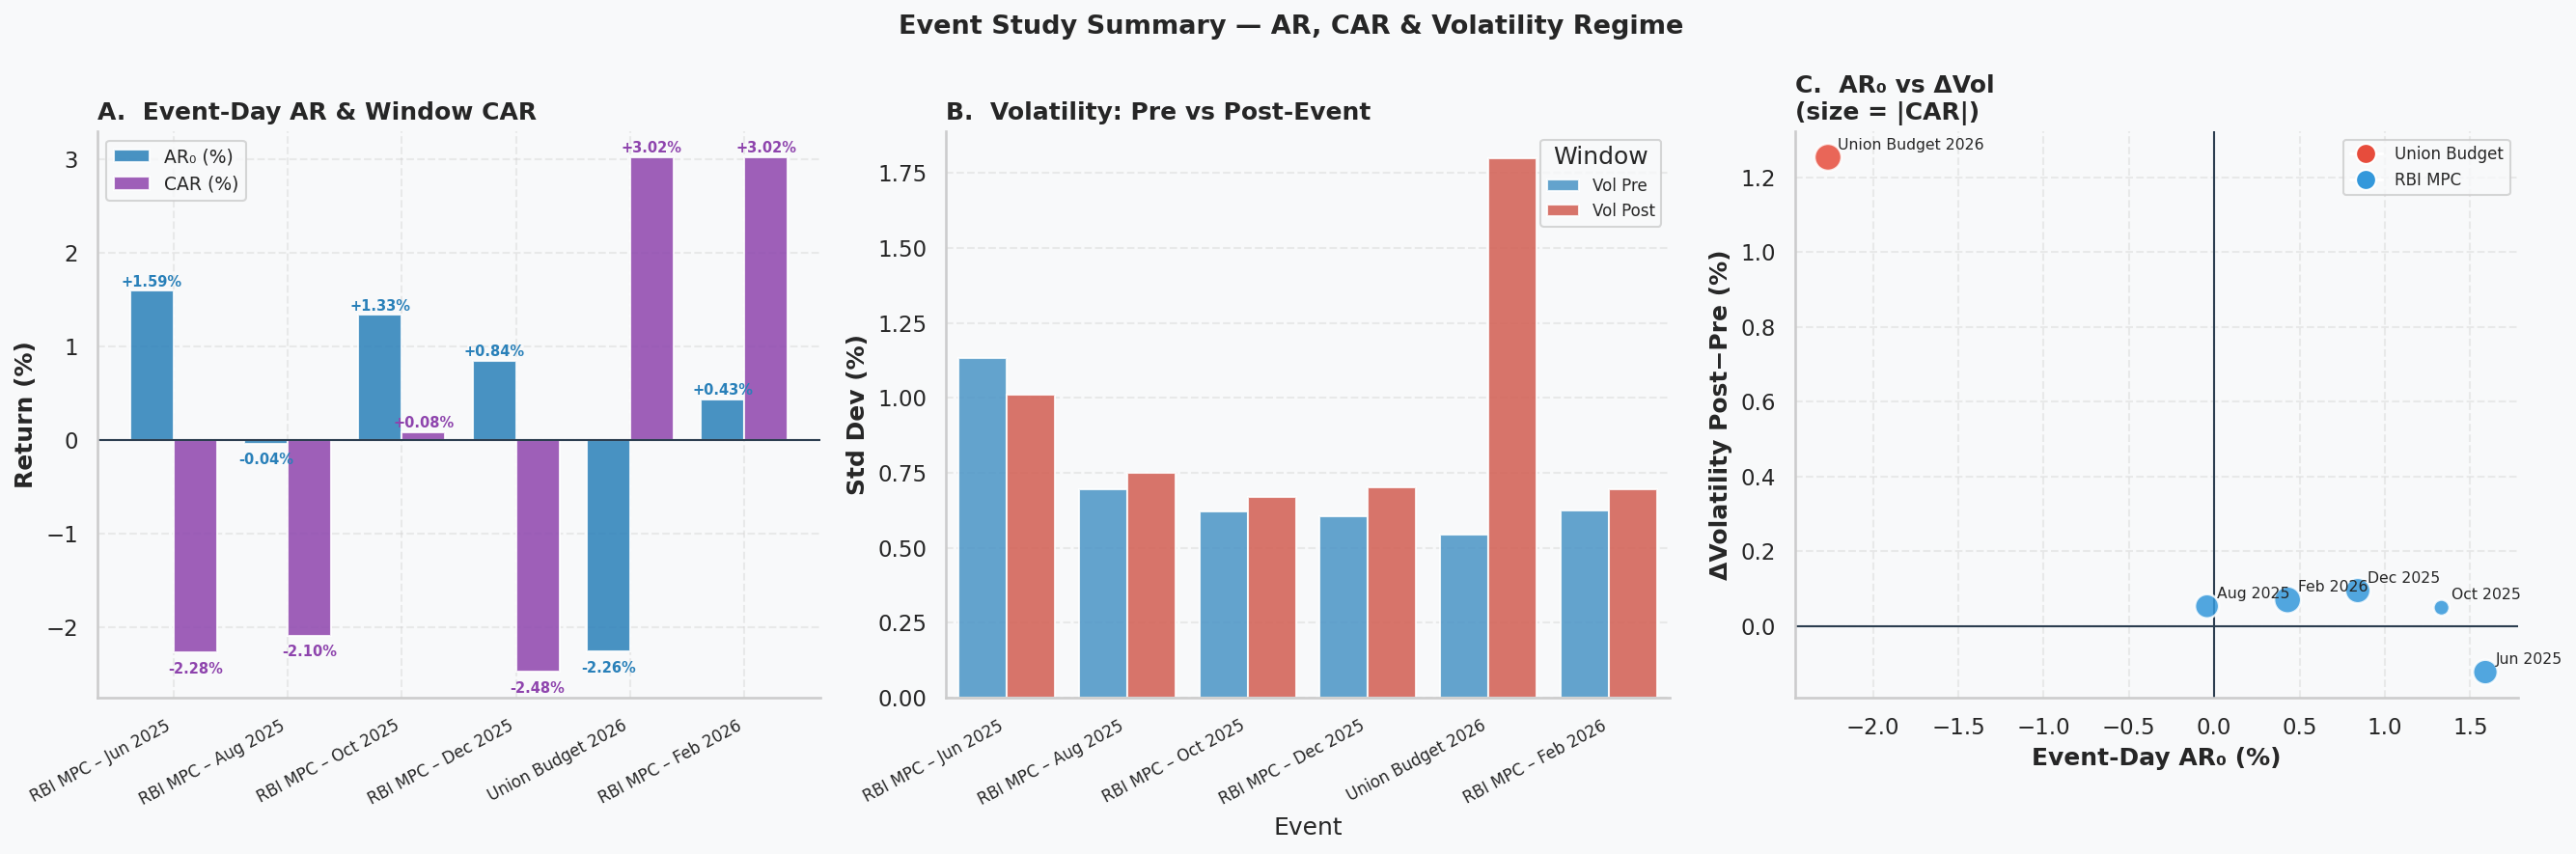

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 7E. [SEABORN] FIGURE 5 — VOLATILITY REGIME + AR/CAR SUMMARY
# ══════════════════════════════════════════════════════════════════════

summary_rows = []
for name, res in results.items():
    short = name.split('\n')[0]
    etype = 'Union Budget' if 'Budget' in name else 'RBI MPC'
    stats_r = ttest_results.get(name, {})
    summary_rows.append({
        'Event':    short,
        'Type':     etype,
        'AR₀':      res['ar_event'],
        'CAR':      res['car_total'],
        'Vol Pre':  res['vol_pre'],
        'Vol Post': res['vol_post'],
        'ΔVol':     res['vol_post'] - res['vol_pre'],
        'p-value':  stats_r.get('t1_pval', 1.0),
        'Sig':      stats_r.get('t1_sig', 'n.s.'),
    })

summary_df = pd.DataFrame(summary_rows)
palette_type = {'Union Budget': '#E74C3C', 'RBI MPC': '#3498DB'}

fig5s, axes5s = plt.subplots(1, 3, figsize=(18, 6), facecolor='#F8F9FA')
fig5s.suptitle('Event Study Summary — AR, CAR & Volatility Regime',
               fontsize=13, fontweight='bold')

# ── Panel A: AR₀ + CAR grouped bars ────────────────────────────────────
x        = np.arange(len(summary_df))
w        = 0.38
bar_ar   = axes5s[0].bar(x - w/2, summary_df['AR₀'], w,
                          color='#2980B9', alpha=0.85, edgecolor='white', label='AR₀ (%)')
bar_car  = axes5s[0].bar(x + w/2, summary_df['CAR'], w,
                          color='#8E44AD', alpha=0.85, edgecolor='white', label='CAR (%)')
axes5s[0].axhline(0, color='#2C3E50', linewidth=1)
axes5s[0].set_xticks(x)
axes5s[0].set_xticklabels(summary_df['Event'], rotation=28, ha='right', fontsize=8)
axes5s[0].set_ylabel('Return (%)', fontweight='bold')
axes5s[0].set_title('A.  Event-Day AR & Window CAR', fontweight='bold', loc='left')
axes5s[0].legend(fontsize=9)
for bar, v in zip(bar_ar, summary_df['AR₀']):
    axes5s[0].text(bar.get_x()+bar.get_width()/2,
                   v+(0.05 if v>=0 else -0.22), f'{v:+.2f}%',
                   ha='center', fontsize=7, fontweight='bold', color='#2980B9')
for bar, v in zip(bar_car, summary_df['CAR']):
    axes5s[0].text(bar.get_x()+bar.get_width()/2,
                   v+(0.05 if v>=0 else -0.22), f'{v:+.2f}%',
                   ha='center', fontsize=7, fontweight='bold', color='#8E44AD')

# ── Panel B: Pre vs Post Vol — Seaborn grouped barplot ─────────────────
vol_long = summary_df[['Event','Type','Vol Pre','Vol Post']].melt(
    id_vars=['Event','Type'], var_name='Window', value_name='Volatility')
sns.barplot(
    data=vol_long,
    x='Event',
    y='Volatility',
    hue='Window',
    ax=axes5s[1],
    palette={'Vol Pre': '#3498DB', 'Vol Post': '#E74C3C'},
    alpha=0.85,
    edgecolor='white',
)
axes5s[1].set_xticklabels(axes5s[1].get_xticklabels(), rotation=28, ha='right', fontsize=8)
axes5s[1].set_ylabel('Std Dev (%)', fontweight='bold')
axes5s[1].set_title('B.  Volatility: Pre vs Post-Event', fontweight='bold', loc='left')
axes5s[1].legend(title='Window', fontsize=8)

# ── Panel C: Scatter — AR₀ vs ΔVol sized by |CAR|, coloured by type ───
scatter_colors = summary_df['Type'].map(palette_type)
sizes          = (summary_df['CAR'].abs() * 40 + 60).clip(60, 400)

sc = axes5s[2].scatter(
    summary_df['AR₀'],
    summary_df['ΔVol'],
    c=scatter_colors,
    s=sizes,
    alpha=0.85,
    edgecolors='white',
    linewidth=1.2,
    zorder=3,
)
axes5s[2].axhline(0, color='#2C3E50', linewidth=1)
axes5s[2].axvline(0, color='#2C3E50', linewidth=1)
for _, row in summary_df.iterrows():
    axes5s[2].annotate(
        row['Event'].replace('RBI MPC – ',''),
        (row['AR₀'], row['ΔVol']),
        textcoords='offset points', xytext=(5, 4), fontsize=7.5
    )
axes5s[2].set_xlabel('Event-Day AR₀ (%)', fontweight='bold')
axes5s[2].set_ylabel('ΔVolatility Post−Pre (%)', fontweight='bold')
axes5s[2].set_title('C.  AR₀ vs ΔVol\n(size = |CAR|)', fontweight='bold', loc='left')

# Custom legend for types
from matplotlib.lines import Line2D
axes5s[2].legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#E74C3C', markersize=10, label='Union Budget'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#3498DB', markersize=10, label='RBI MPC'),
], fontsize=8)

plt.tight_layout()
fig5s.savefig(f'{output_dir}fig5_sns_summary.png', dpi=150, bbox_inches='tight')
print(f"✅ Fig 5 (Seaborn) saved → {output_dir}fig5_sns_summary.png")


In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 8.  FINAL SUMMARY TABLE  (extended with t-test columns)
# ══════════════════════════════════════════════════════════════════════
print("\n" + "=" * 105)
print(f"{'EVENT':<28} {'Date':>11} {'AR₀%':>7} {'CAR%':>7} {'ΔVol%':>7} "
      f"| {'T1 t':>7} {'T1 p':>7} {'T1':>5} | {'T2 t':>7} {'T2 p':>7} {'T2':>5}")
print("-" * 105)
for name, res in results.items():
    if res is None:
        continue
    short  = name.split('\n')[0]
    vc     = res['vol_post'] - res['vol_pre']
    tr     = ttest_results.get(name, {})
    print(
        f"{short:<28} {str(res['event_date'].date()):>11} "
        f"{res['ar_event']:>+7.3f} {res['car_total']:>+7.3f} {vc:>+7.4f} | "
        f"{tr.get('t1_stat', float('nan')):>7.3f} {tr.get('t1_pval', 1.0):>7.4f} {tr.get('t1_sig','—'):>5} | "
        f"{tr.get('t2_stat', float('nan')):>7.3f} {tr.get('t2_pval', 1.0):>7.4f} {tr.get('t2_sig','—'):>5}"
    )
print("=" * 105)
print()
print("LEGEND:")
print("  AR₀%  = Abnormal return on event day (Day 0)")
print("  CAR%  = Cumulative abnormal return over ±5 day window")
print("  ΔVol% = Post-event σ minus pre-event σ (5-day windows)")
print("  T1    = One-sample t-test: H₀: mean(AR_window) = 0")
print("  T2    = Standardised event-day AR: H₀: AR₀ = 0 (Patell-style)")
print("  Sig   = *** p<0.01  ** p<0.05  * p<0.10  n.s. = not significant")
print()
print("✅ All analysis complete. All figures saved to Drive/NIFTY/")



EVENT                               Date    AR₀%    CAR%   ΔVol% |    T1 t    T1 p    T1 |    T2 t    T2 p    T2
---------------------------------------------------------------------------------------------------------
RBI MPC – Jun 2025            2025-06-06  +1.589  -2.278 -0.1229 |  -0.895  0.3916  n.s. |   1.402  0.1714  n.s.
RBI MPC – Aug 2025            2025-08-06  -0.042  -2.099 +0.0531 |  -1.132  0.2841  n.s. |  -0.061  0.9518  n.s.
RBI MPC – Oct 2025            2025-10-01  +1.332  +0.078 +0.0493 |   0.033  0.9743  n.s. |   2.149  0.0401    **
RBI MPC – Dec 2025            2025-12-05  +0.842  -2.484 +0.0949 |  -1.293  0.2251  n.s. |   1.389  0.1754  n.s.
Union Budget 2026             2026-02-01  -2.264  +3.015 +1.2533 |   0.639  0.5374  n.s. |  -4.159  0.0003   ***
RBI MPC – Feb 2026            2026-02-06  +0.430  +3.018 +0.0701 |   0.668  0.5193  n.s. |   0.688  0.4969  n.s.

LEGEND:
  AR₀%  = Abnormal return on event day (Day 0)
  CAR%  = Cumulative abnormal return over ±5 d

✅ Figure 1 saved to Drive: /content/drive/My Drive/NIFTY/fig1_overview.png
✅ Figure 2 saved to Drive: /content/drive/My Drive/NIFTY/fig2_abnormal_returns.png
✅ Figure 3 saved to Drive: /content/drive/My Drive/NIFTY/fig3_car.png
✅ Figure 4 saved to Drive: /content/drive/My Drive/NIFTY/fig4_volatility.png
✅ Figure 5 saved to Drive: /content/drive/My Drive/NIFTY/fig5_summary_ar_car.png


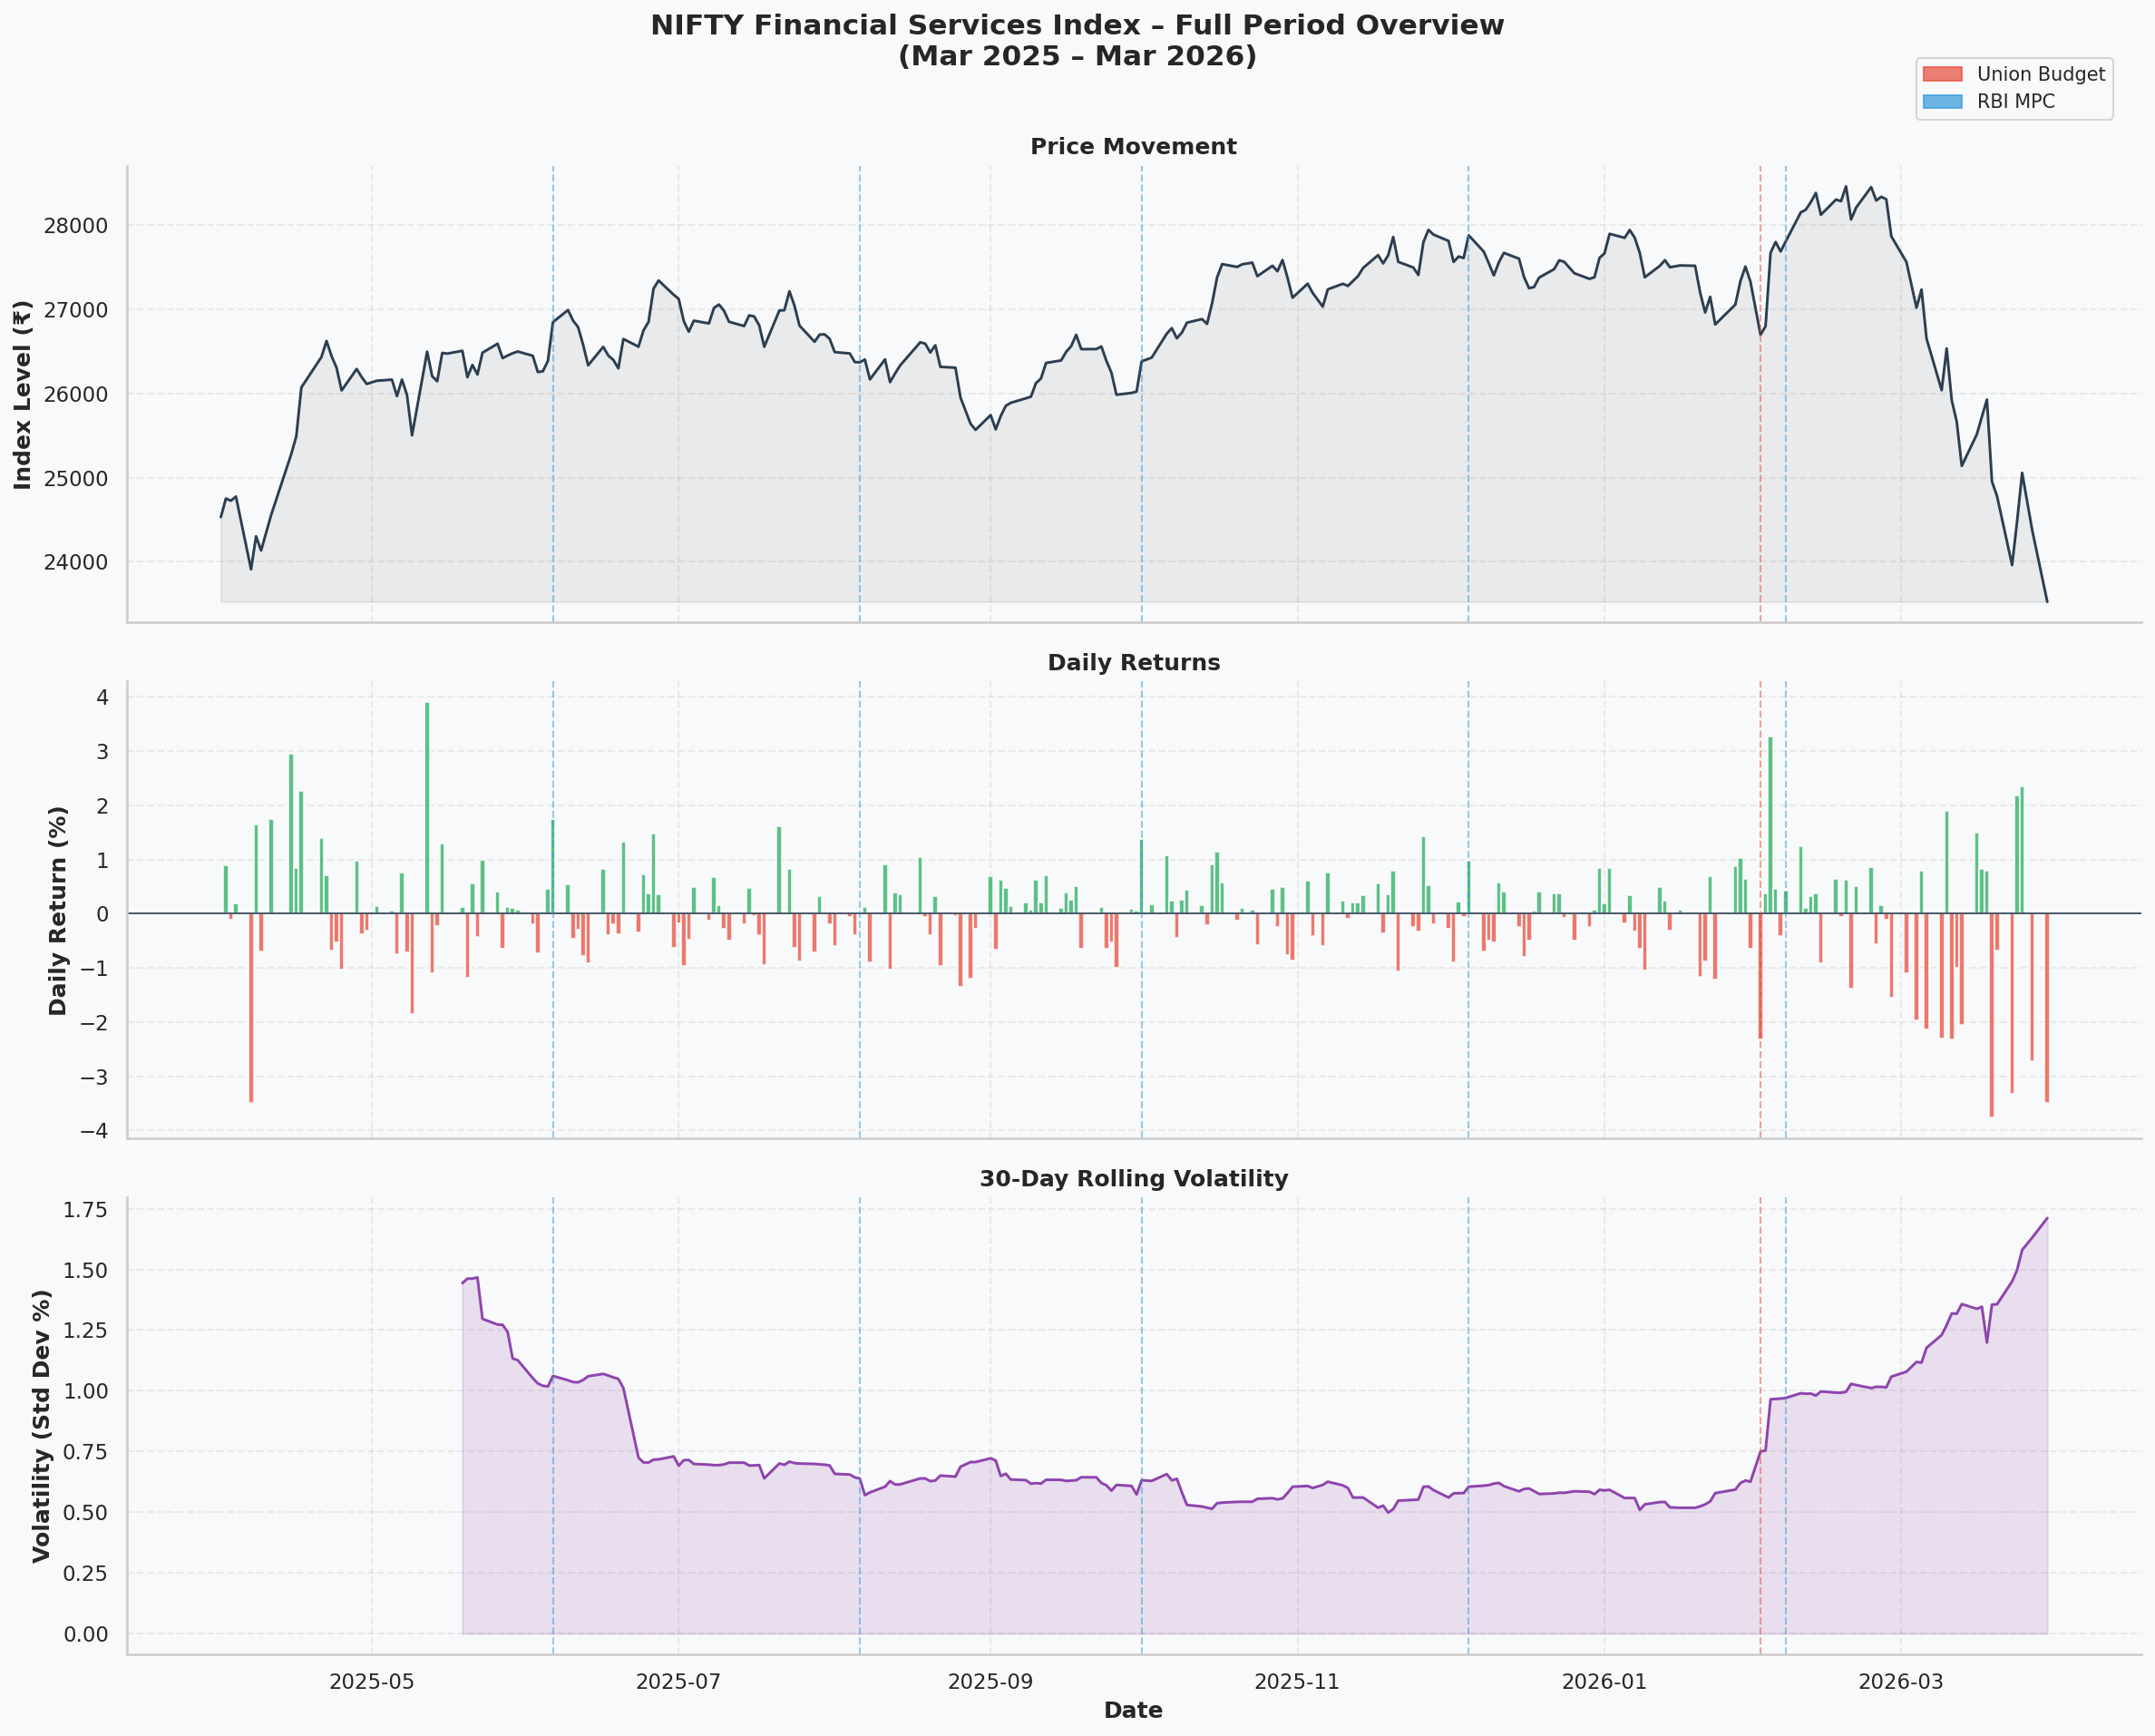

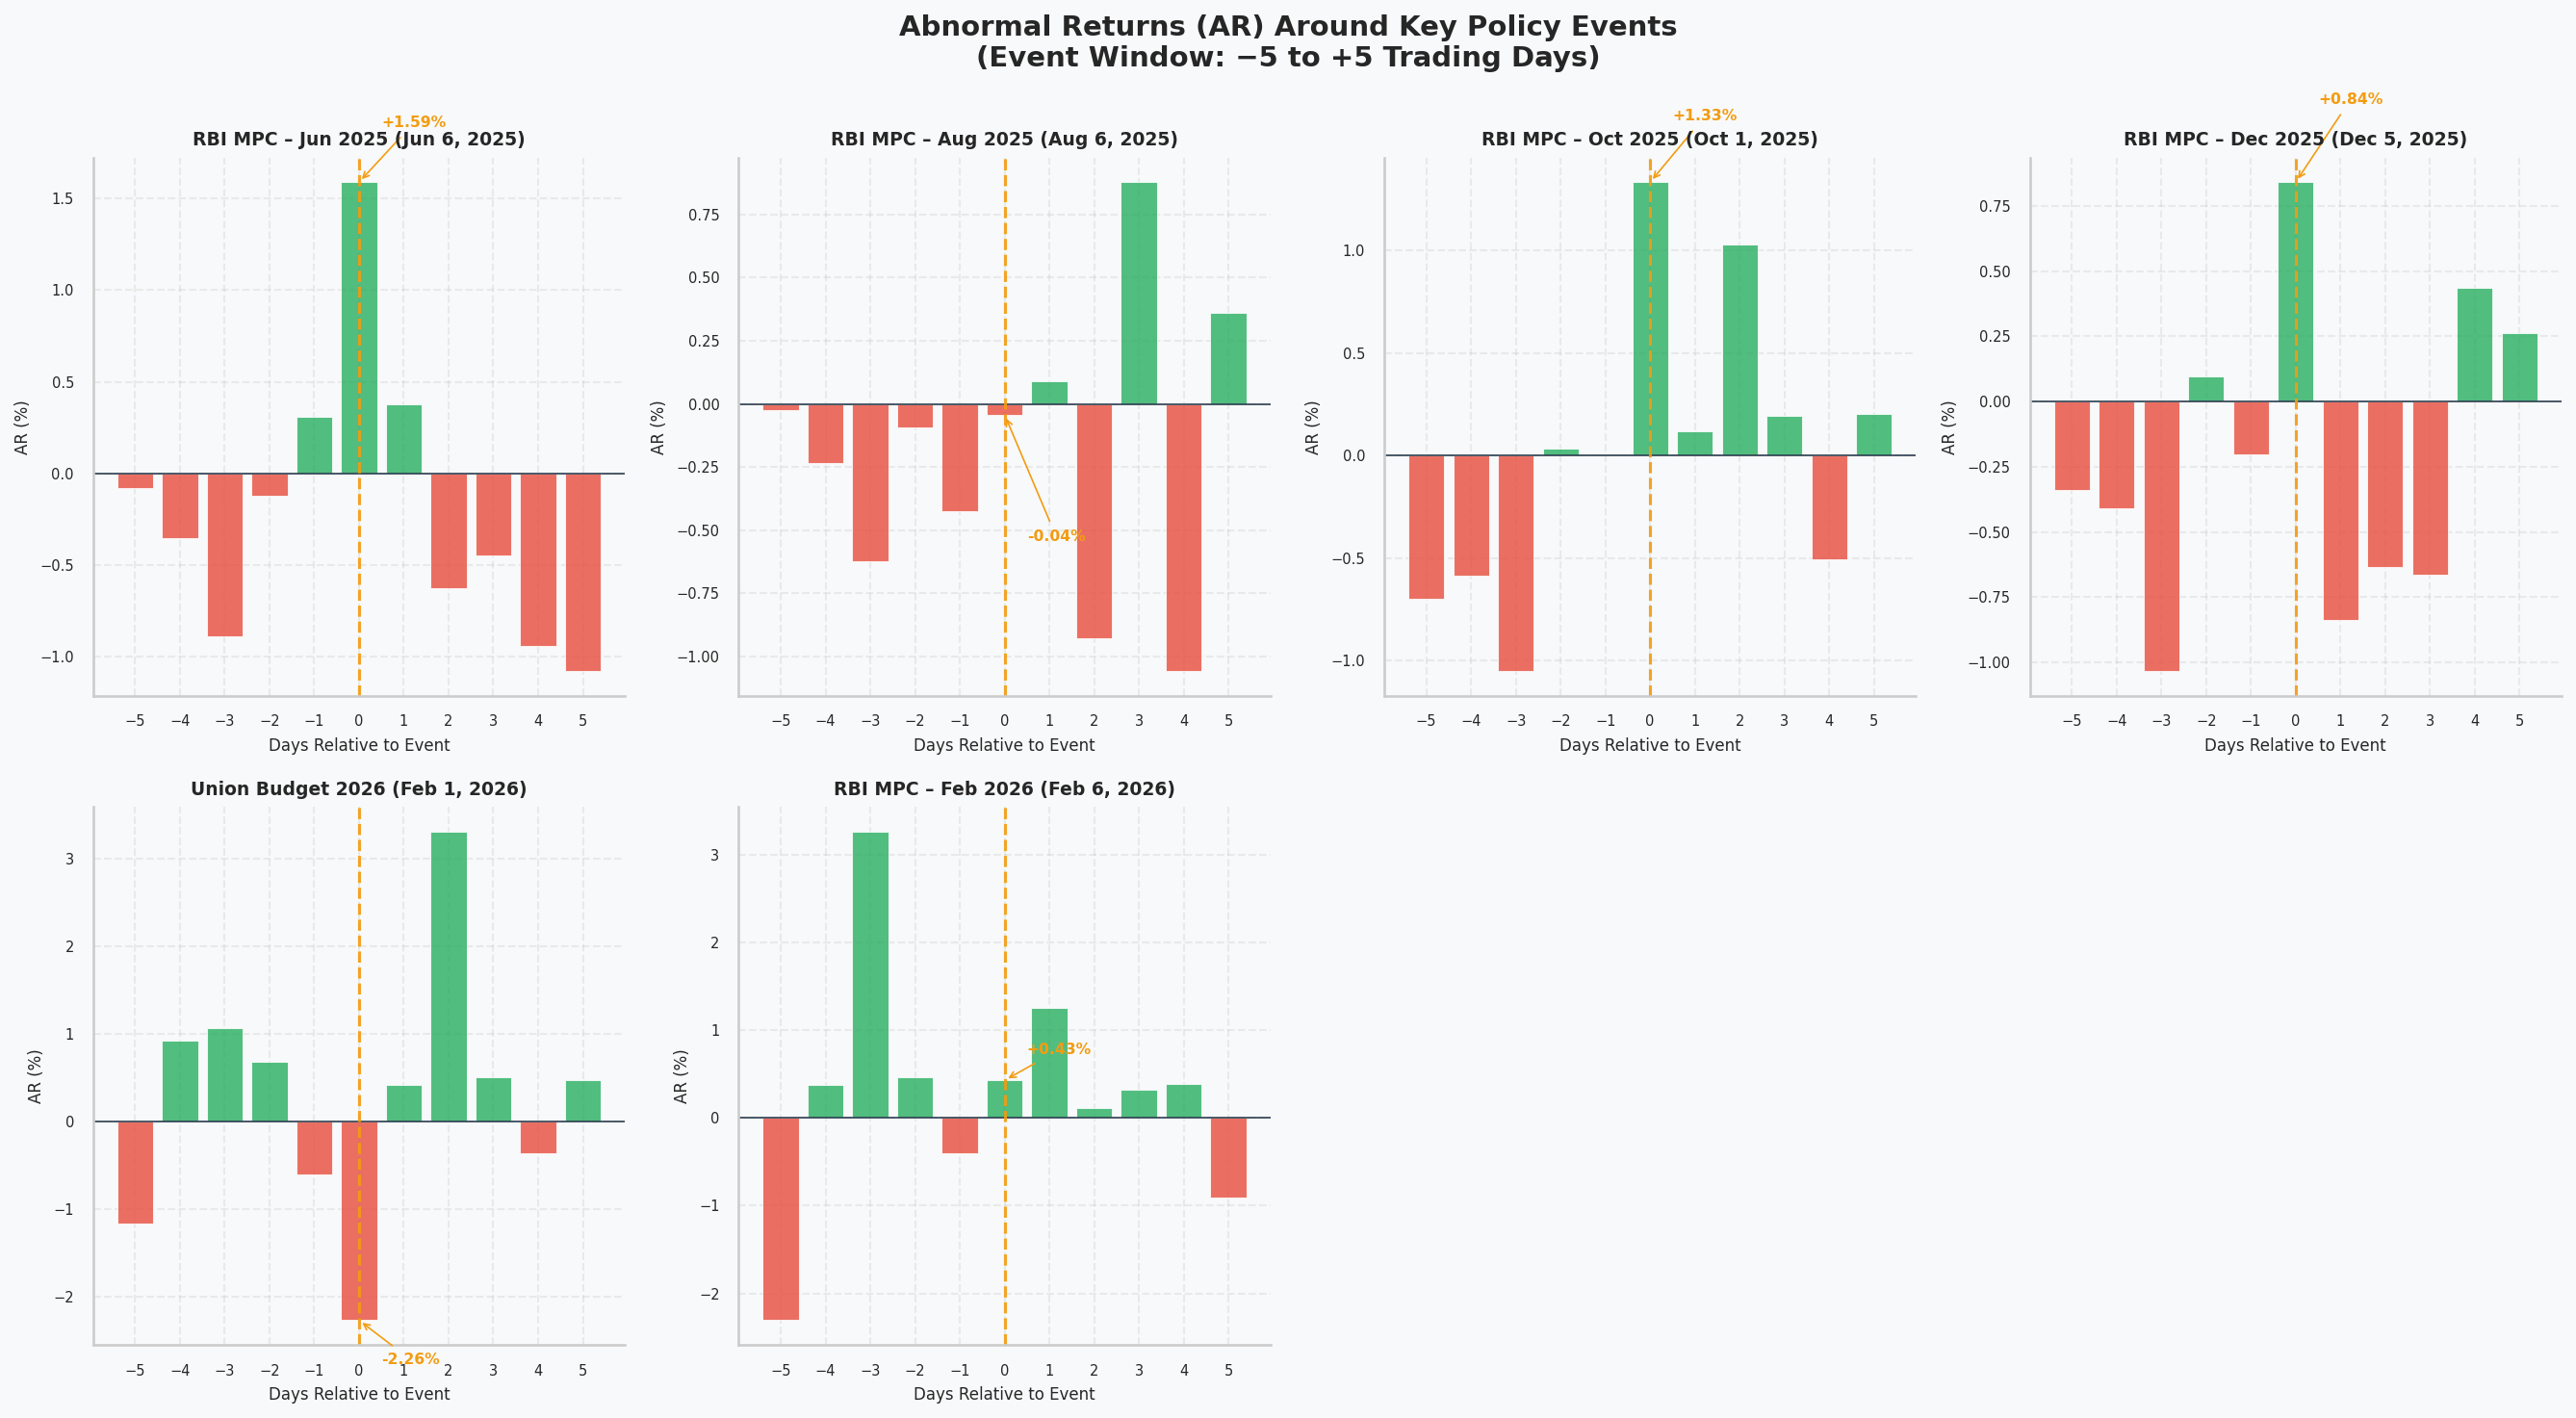

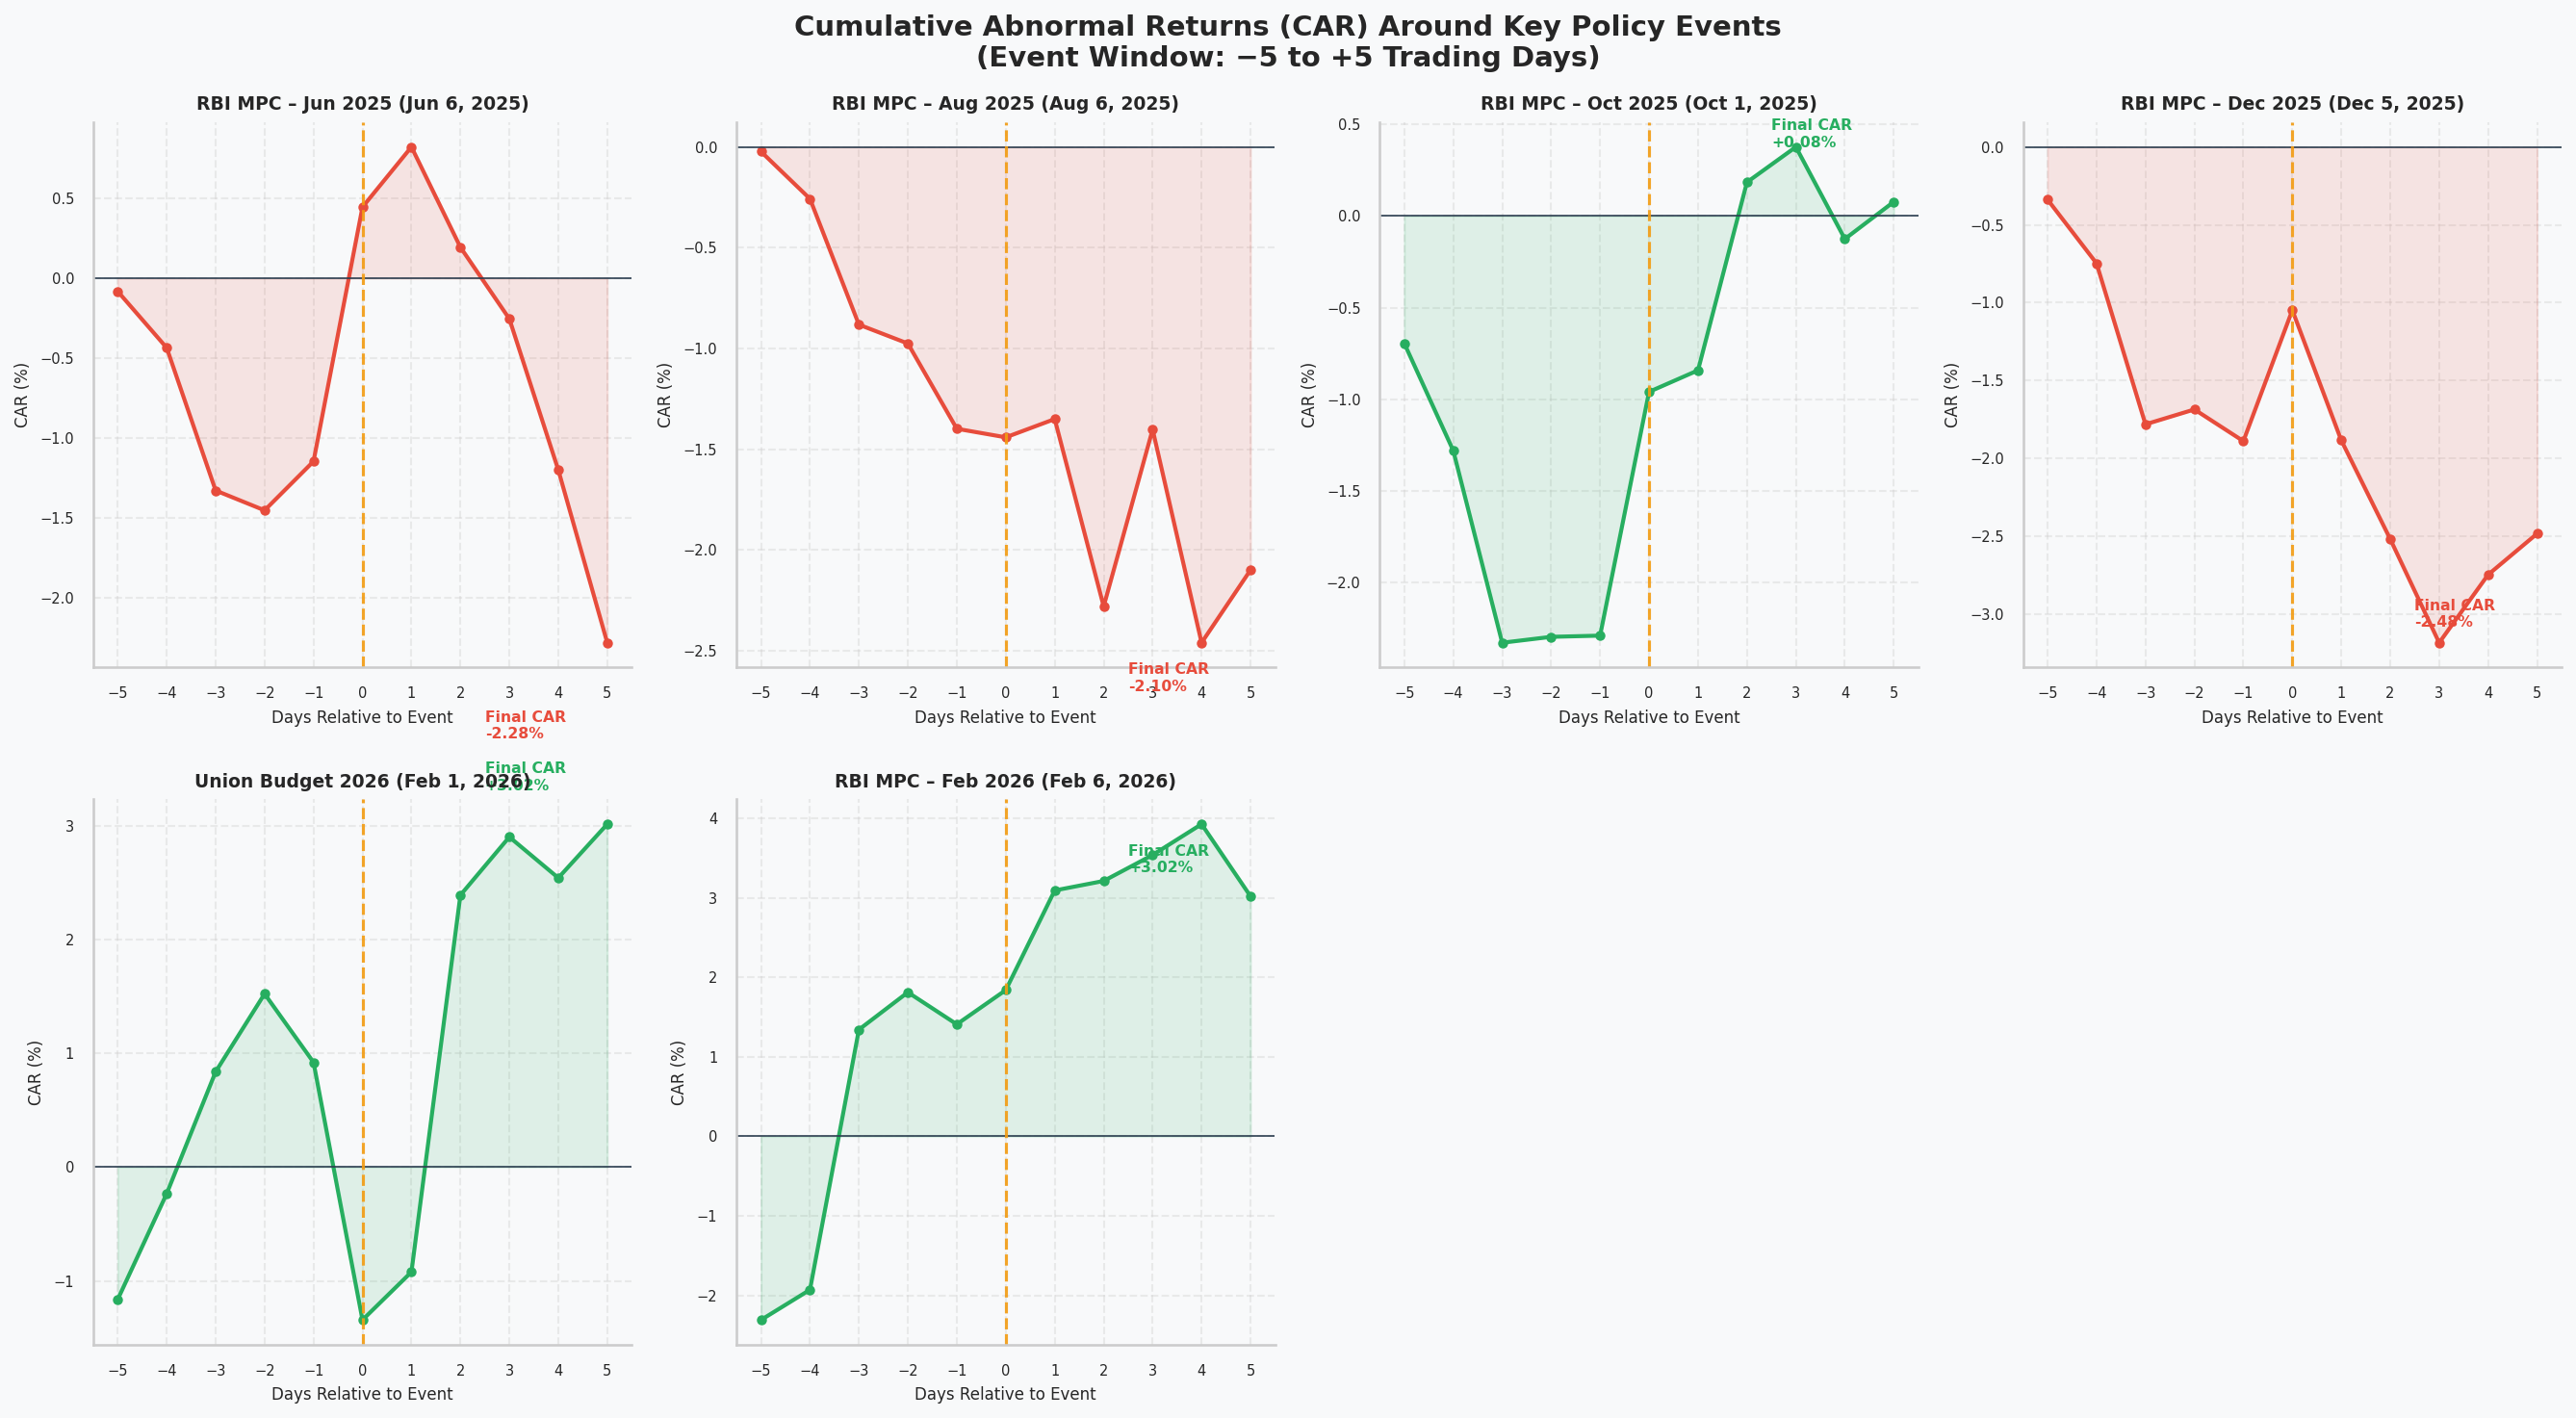

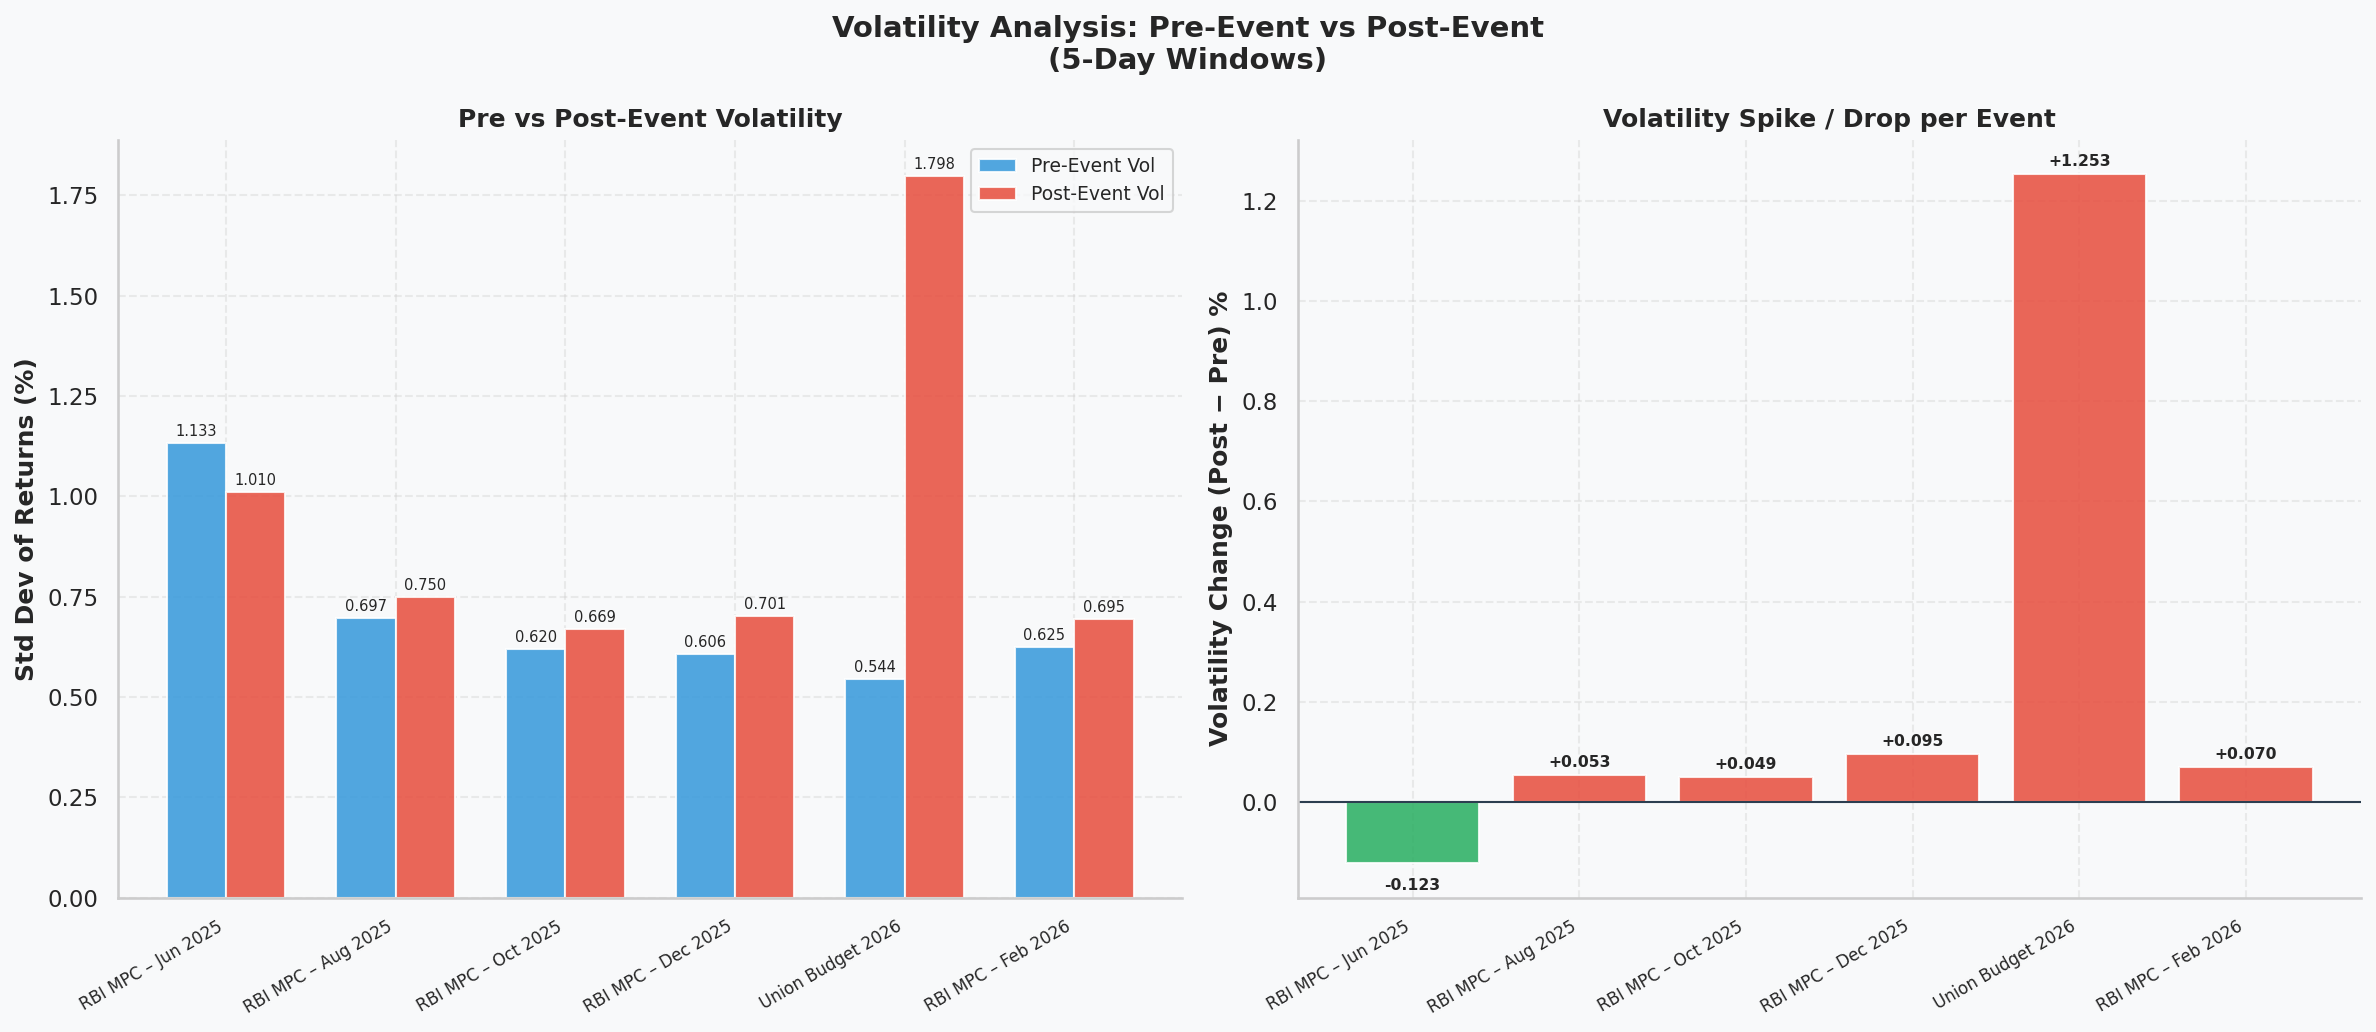

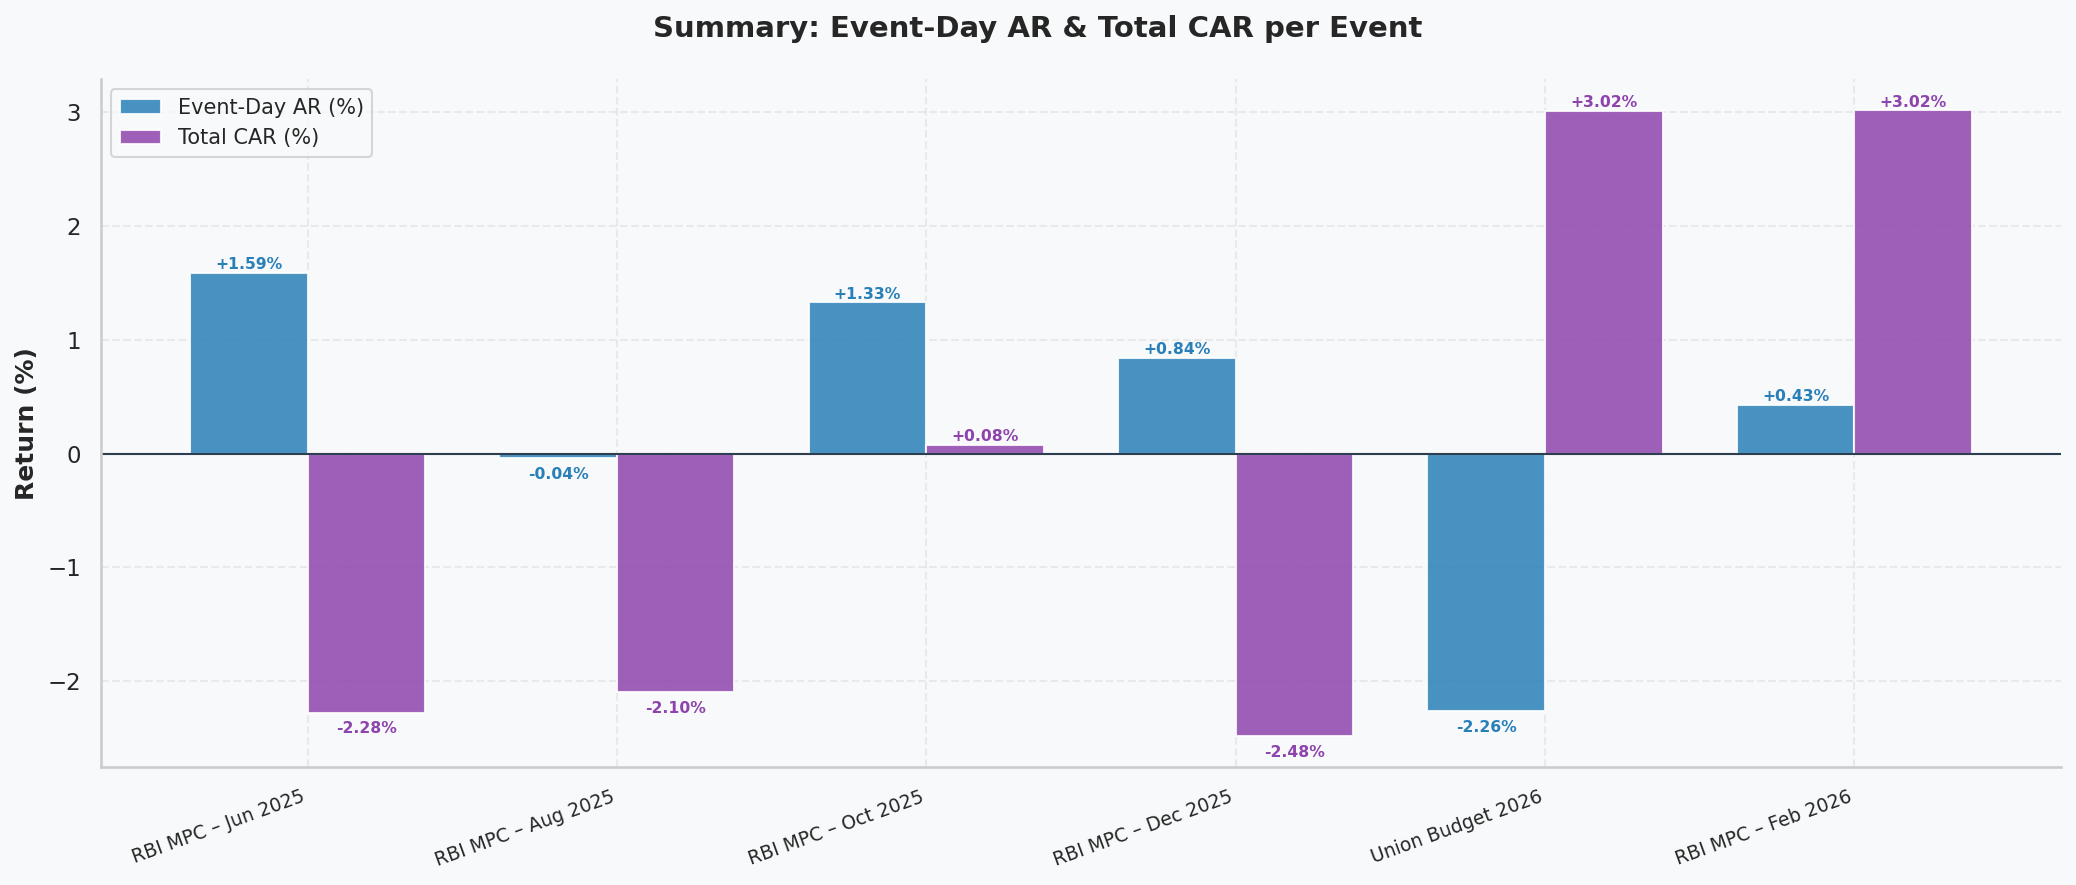

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# 6.  VISUALISATION
# ══════════════════════════════════════════════════════════════════════

# ── EVENT COLORS ──────────────────────────────────────────────────────
event_colors = {
    'Union Budget 2025\n(Feb 1, 2025)': '#E74C3C',
    'RBI MPC – Apr 2025\n(Apr 9, 2025)': '#3498DB',
    'RBI MPC – Jun 2025\n(Jun 6, 2025)': '#3498DB',
    'RBI MPC – Aug 2025\n(Aug 6, 2025)': '#3498DB',
    'RBI MPC – Oct 2025\n(Oct 1, 2025)': '#3498DB',
    'RBI MPC – Dec 2025\n(Dec 5, 2025)': '#3498DB',
    'Union Budget 2026\n(Feb 1, 2026)': '#E74C3C',
    'RBI MPC – Feb 2026\n(Feb 6, 2026)': '#3498DB',
}

# ────────────────────────────────────────────────────────────────────
# FIGURE 1: PRICE + RETURN + VOLATILITY OVERVIEW
# ────────────────────────────────────────────────────────────────────
fig1, axes = plt.subplots(3, 1, figsize=(16, 13), sharex=True)
fig1.suptitle('NIFTY Financial Services Index – Full Period Overview\n(Mar 2025 – Mar 2026)',
              fontsize=15, fontweight='bold', y=0.98)

ax1, ax2, ax3 = axes

# ── Price ─────────────────────────────────────────────────────────────
ax1.plot(df['Date'], df['Close'], color='#2C3E50', linewidth=1.4, label='Close Price')
ax1.fill_between(df['Date'], df['Close'], df['Close'].min(), alpha=0.08, color='#2C3E50')
ax1.set_ylabel('Index Level (₹)', fontweight='bold')
ax1.set_title('Price Movement', fontweight='bold')

for name, res in results.items():
    ax1.axvline(res['event_date'], color=event_colors[name], alpha=0.5,
                linestyle='--', linewidth=1)

# ── Daily Returns ─────────────────────────────────────────────────────
colors_ret = ['#27AE60' if r >= 0 else '#E74C3C' for r in df['Return'].fillna(0)]
ax2.bar(df['Date'], df['Return'].fillna(0), color=colors_ret, alpha=0.75, width=1)
ax2.axhline(0, color='#2C3E50', linewidth=0.8)
ax2.set_ylabel('Daily Return (%)', fontweight='bold')
ax2.set_title('Daily Returns', fontweight='bold')

for name, res in results.items():
    ax2.axvline(res['event_date'], color=event_colors[name], alpha=0.5,
                linestyle='--', linewidth=1)

# ── 30-day Rolling Volatility ─────────────────────────────────────────
ax3.plot(df['Date'], df['Vol30'], color='#8E44AD', linewidth=1.4, label='30-day Std Dev')
ax3.fill_between(df['Date'], df['Vol30'], alpha=0.15, color='#8E44AD')
ax3.set_ylabel('Volatility (Std Dev %)', fontweight='bold')
ax3.set_title('30-Day Rolling Volatility', fontweight='bold')
ax3.set_xlabel('Date', fontweight='bold')

for name, res in results.items():
    ax3.axvline(res['event_date'], color=event_colors[name], alpha=0.5,
                linestyle='--', linewidth=1)

# Shared legend
budget_patch = mpatches.Patch(color='#E74C3C', alpha=0.7, label='Union Budget')
rbi_patch    = mpatches.Patch(color='#3498DB', alpha=0.7, label='RBI MPC')
fig1.legend(handles=[budget_patch, rbi_patch], loc='upper right',
            frameon=True, fontsize=10, bbox_to_anchor=(0.98, 0.96))

plt.tight_layout(rect=[0, 0, 1, 0.97])
fig1.savefig(f'{output_dir}fig1_overview.png', dpi=150, bbox_inches='tight')
print(f"✅ Figure 1 saved to Drive: {output_dir}fig1_overview.png")

# ────────────────────────────────────────────────────────────────────
# FIGURE 2: ABNORMAL RETURNS PER EVENT (2×4 grid)
# ────────────────────────────────────────────────────────────────────
n_events = len(results)
ncols = 4
nrows = (n_events + ncols - 1) // ncols

fig2, axes2 = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
fig2.suptitle('Abnormal Returns (AR) Around Key Policy Events\n(Event Window: −5 to +5 Trading Days)',
              fontsize=14, fontweight='bold')

axes2_flat = axes2.flatten() if n_events > 1 else [axes2]

for idx, (name, res) in enumerate(results.items()):
    ax = axes2_flat[idx]
    ev  = res['ev_df']
    days = ev['day'].values
    ar   = ev['AR'].values

    bar_colors = ['#27AE60' if v >= 0 else '#E74C3C' for v in ar]
    ax.bar(days, ar, color=bar_colors, alpha=0.8, edgecolor='white', linewidth=0.5)
    ax.axhline(0, color='#2C3E50', linewidth=0.8)
    ax.axvline(0, color='#F39C12', linewidth=1.5, linestyle='--', alpha=0.9, label='Event Day')

    short_name = name.replace('\n', ' ')
    ax.set_title(short_name, fontsize=9, fontweight='bold')
    ax.set_xlabel('Days Relative to Event', fontsize=8)
    ax.set_ylabel('AR (%)', fontsize=8)
    ax.set_xticks(range(-5, 6))
    ax.tick_params(labelsize=7)

    # Annotate event-day AR
    ar0 = res['ar_event']
    ax.annotate(f'{ar0:+.2f}%', xy=(0, ar0),
                xytext=(0.5, ar0 + (0.3 if ar0 >= 0 else -0.5)),
                fontsize=7.5, color='#F39C12', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='#F39C12', lw=0.8))

# Hide empty subplots
for j in range(idx + 1, len(axes2_flat)):
    axes2_flat[j].set_visible(False)

plt.tight_layout()
fig2.savefig(f'{output_dir}fig2_abnormal_returns.png', dpi=150, bbox_inches='tight')
print(f"✅ Figure 2 saved to Drive: {output_dir}fig2_abnormal_returns.png")

# ────────────────────────────────────────────────────────────────────
# FIGURE 3: CUMULATIVE ABNORMAL RETURNS (CAR) PER EVENT
# ────────────────────────────────────────────────────────────────────
fig3, axes3 = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
fig3.suptitle('Cumulative Abnormal Returns (CAR) Around Key Policy Events\n(Event Window: −5 to +5 Trading Days)',
              fontsize=14, fontweight='bold')

axes3_flat = axes3.flatten() if n_events > 1 else [axes3]

for idx, (name, res) in enumerate(results.items()):
    ax = axes3_flat[idx]
    ev   = res['ev_df']
    days = ev['day'].values
    car  = ev['CAR'].values

    color_line = '#E74C3C' if car[-1] < 0 else '#27AE60'
    ax.plot(days, car, color=color_line, linewidth=2, marker='o', markersize=4)
    ax.fill_between(days, car, 0, alpha=0.12, color=color_line)
    ax.axhline(0, color='#2C3E50', linewidth=0.8)
    ax.axvline(0, color='#F39C12', linewidth=1.5, linestyle='--', alpha=0.9)

    short_name = name.replace('\n', ' ')
    ax.set_title(short_name, fontsize=9, fontweight='bold')
    ax.set_xlabel('Days Relative to Event', fontsize=8)
    ax.set_ylabel('CAR (%)', fontsize=8)
    ax.set_xticks(range(-5, 6))
    ax.tick_params(labelsize=7)

    # Final CAR label
    ax.annotate(f'Final CAR\n{car[-1]:+.2f}%', xy=(days[-1], car[-1]),
                xytext=(days[-1] - 2.5, car[-1] + (0.3 if car[-1] >= 0 else -0.6)),
                fontsize=7.5, color=color_line, fontweight='bold')

for j in range(idx + 1, len(axes3_flat)):
    axes3_flat[j].set_visible(False)

plt.tight_layout()
fig3.savefig(f'{output_dir}fig3_car.png', dpi=150, bbox_inches='tight')
print(f"✅ Figure 3 saved to Drive: {output_dir}fig3_car.png")

# ────────────────────────────────────────────────────────────────────
# FIGURE 4: VOLATILITY COMPARISON (Pre vs Post)
# ────────────────────────────────────────────────────────────────────
fig4, axes4 = plt.subplots(1, 2, figsize=(16, 7))
fig4.suptitle('Volatility Analysis: Pre-Event vs Post-Event\n(5-Day Windows)',
              fontsize=14, fontweight='bold')

short_names = [n.split('\n')[0] for n in results.keys()]
vol_pre  = [r['vol_pre']  for r in results.values()]
vol_post = [r['vol_post'] for r in results.values()]

x = np.arange(len(short_names))
w = 0.35

ax4a, ax4b = axes4

# Grouped bar
bars1 = ax4a.bar(x - w/2, vol_pre,  w, label='Pre-Event Vol',  color='#3498DB', alpha=0.85, edgecolor='white')
bars2 = ax4a.bar(x + w/2, vol_post, w, label='Post-Event Vol', color='#E74C3C', alpha=0.85, edgecolor='white')
ax4a.set_xticks(x)
ax4a.set_xticklabels(short_names, rotation=30, ha='right', fontsize=8)
ax4a.set_ylabel('Std Dev of Returns (%)', fontweight='bold')
ax4a.set_title('Pre vs Post-Event Volatility', fontweight='bold')
ax4a.legend(fontsize=9)

# Annotate bars
for b in bars1:
    ax4a.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
              f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=7)
for b in bars2:
    ax4a.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
              f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=7)

# Volatility change scatter
vol_change = [post - pre for pre, post in zip(vol_pre, vol_post)]
colors_vc  = ['#E74C3C' if v > 0 else '#27AE60' for v in vol_change]

bars3 = ax4b.bar(x, vol_change, color=colors_vc, alpha=0.85, edgecolor='white')
ax4b.axhline(0, color='#2C3E50', linewidth=1)
ax4b.set_xticks(x)
ax4b.set_xticklabels(short_names, rotation=30, ha='right', fontsize=8)
ax4b.set_ylabel('Volatility Change (Post − Pre) %', fontweight='bold')
ax4b.set_title('Volatility Spike / Drop per Event', fontweight='bold')

for b, v in zip(bars3, vol_change):
    ax4b.text(b.get_x() + b.get_width()/2,
              b.get_height() + (0.01 if v >= 0 else -0.06),
              f'{v:+.3f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

plt.tight_layout()
fig4.savefig(f'{output_dir}fig4_volatility.png', dpi=150, bbox_inches='tight')
print(f"✅ Figure 4 saved to Drive: {output_dir}fig4_volatility.png")

# ────────────────────────────────────────────────────────────────────
# FIGURE 5: EVENT-DAY AR + CAR SUMMARY HEATMAP STYLE
# ────────────────────────────────────────────────────────────────────
fig5, ax5 = plt.subplots(figsize=(14, 6))
fig5.suptitle('Summary: Event-Day AR & Total CAR per Event', fontsize=14, fontweight='bold')

short_names = [n.split('\n')[0] for n in results.keys()]
ar_vals  = [r['ar_event']  for r in results.values()]
car_vals = [r['car_total'] for r in results.values()]

x = np.arange(len(short_names))
w = 0.38

b1 = ax5.bar(x - w/2, ar_vals,  w, label='Event-Day AR (%)',  color='#2980B9', alpha=0.85, edgecolor='white')
b2 = ax5.bar(x + w/2, car_vals, w, label='Total CAR (%)',     color='#8E44AD', alpha=0.85, edgecolor='white')
ax5.axhline(0, color='#2C3E50', linewidth=1)
ax5.set_xticks(x)
ax5.set_xticklabels(short_names, rotation=20, ha='right', fontsize=9)
ax5.set_ylabel('Return (%)', fontweight='bold')
ax5.legend(fontsize=10)

for b, v in zip(b1, ar_vals):
    ax5.text(b.get_x() + b.get_width()/2,
             b.get_height() + (0.03 if v >= 0 else -0.18),
             f'{v:+.2f}%', ha='center', fontsize=7.5, color='#2980B9', fontweight='bold')

for b, v in zip(b2, car_vals):
    ax5.text(b.get_x() + b.get_width()/2,
             b.get_height() + (0.03 if v >= 0 else -0.18),
             f'{v:+.2f}%', ha='center', fontsize=7.5, color='#8E44AD', fontweight='bold')

plt.tight_layout()
fig5.savefig(f'{output_dir}fig5_summary_ar_car.png', dpi=150, bbox_inches='tight')
print(f"✅ Figure 5 saved to Drive: {output_dir}fig5_summary_ar_car.png")


✅ Figure 6 (Master) saved to Drive: /content/drive/My Drive/NIFTY/fig6_master.png


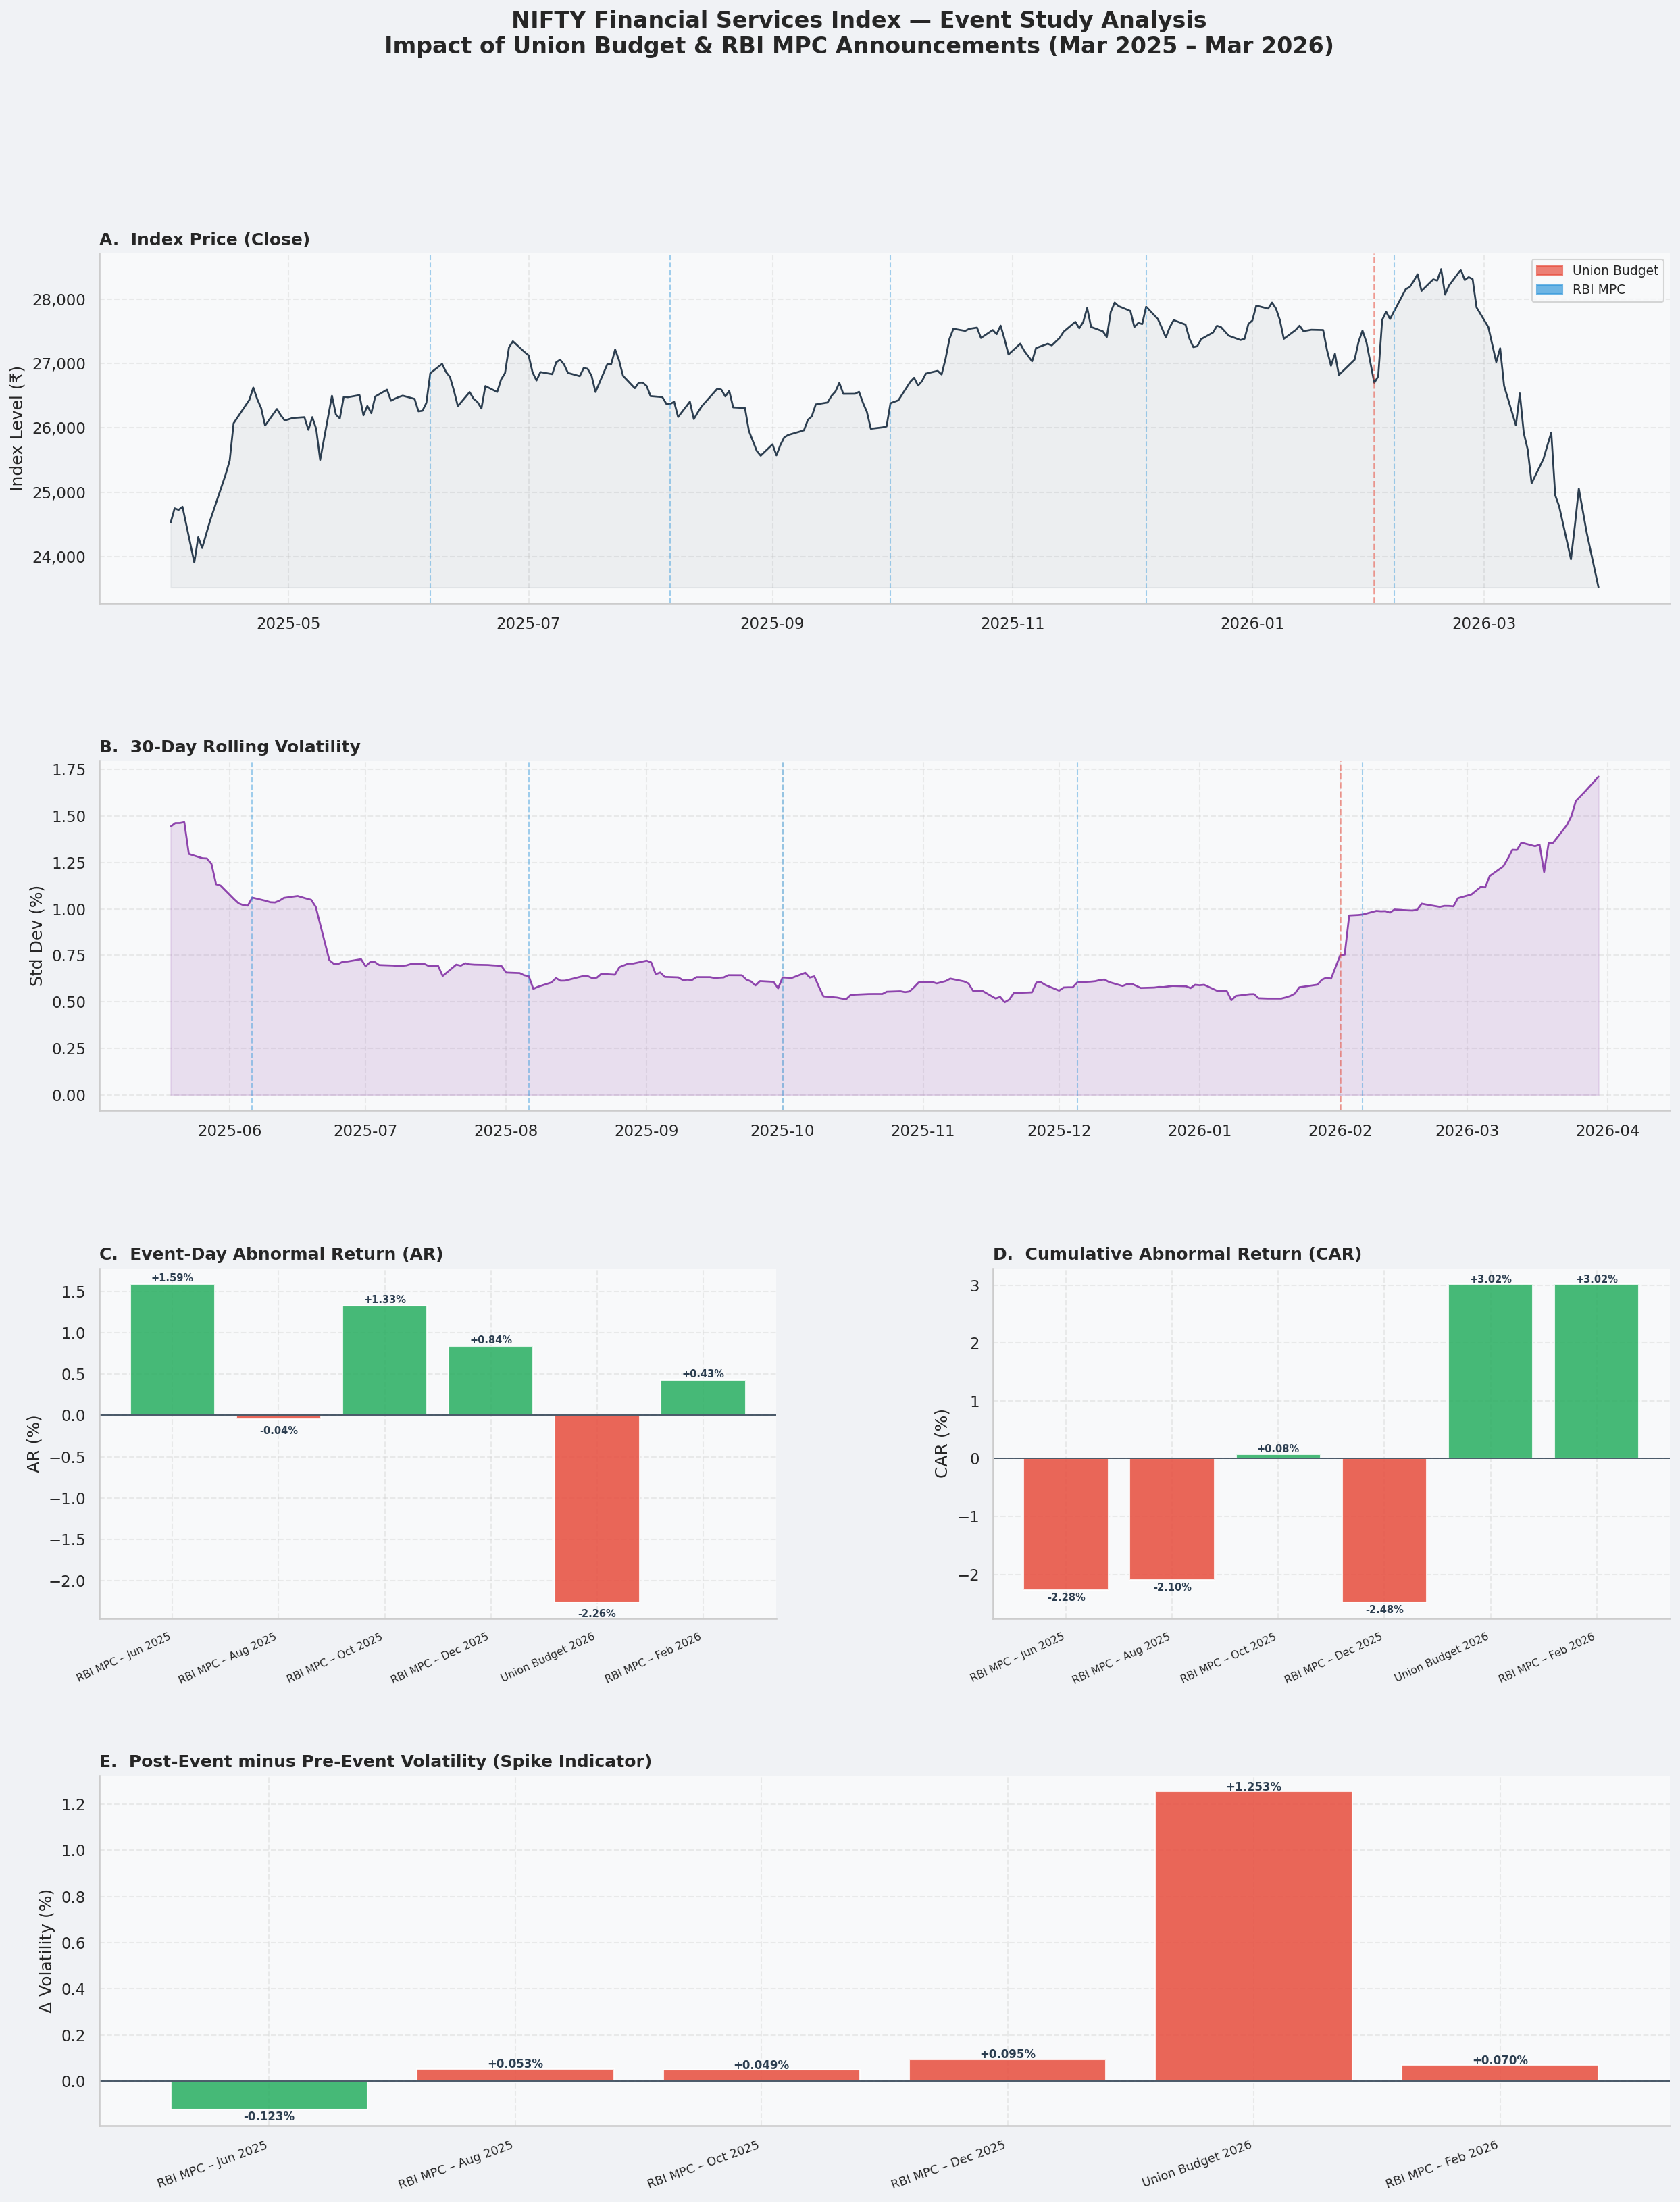

In [ ]:
# ════════════════════════════════════════════════════════════════════
# 7.  COMBINED MASTER FIGURE  (publication-ready)
# ════════════════════════════════════════════════════════════════════
fig6 = plt.figure(figsize=(20, 24))
fig6.patch.set_facecolor('#F0F2F5')
gs  = gridspec.GridSpec(4, 2, figure=fig6, hspace=0.45, wspace=0.32)

fig6.suptitle(
    'NIFTY Financial Services Index — Event Study Analysis\n'
    'Impact of Union Budget & RBI MPC Announcements (Mar 2025 – Mar 2026)',
    fontsize=16, fontweight='bold', y=0.98
)

# Panel A: Price
axA = fig6.add_subplot(gs[0, :])
axA.plot(df['Date'], df['Close'], color='#2C3E50', linewidth=1.3)
axA.fill_between(df['Date'], df['Close'], df['Close'].min(), alpha=0.06, color='#2C3E50')
axA.set_title('A.  Index Price (Close)', fontweight='bold', loc='left')
axA.set_ylabel('Index Level (₹)')
axA.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))

budget_dates = [r['event_date'] for n, r in results.items() if 'Budget' in n]
rbi_dates    = [r['event_date'] for n, r in results.items() if 'RBI' in n]

for d in budget_dates:
    axA.axvline(d, color='#E74C3C', alpha=0.55, linestyle='--', linewidth=1.2)
for d in rbi_dates:
    axA.axvline(d, color='#3498DB', alpha=0.45, linestyle='--', linewidth=1.0)

axA.legend(handles=[
    mpatches.Patch(color='#E74C3C', alpha=0.7, label='Union Budget'),
    mpatches.Patch(color='#3498DB', alpha=0.7, label='RBI MPC'),
], fontsize=9, loc='upper right')

# Panel B: Rolling Volatility
axB = fig6.add_subplot(gs[1, :])
axB.plot(df['Date'], df['Vol30'], color='#8E44AD', linewidth=1.3)
axB.fill_between(df['Date'], df['Vol30'], alpha=0.15, color='#8E44AD')
axB.set_title('B.  30-Day Rolling Volatility', fontweight='bold', loc='left')
axB.set_ylabel('Std Dev (%)')
for d in budget_dates:
    axB.axvline(d, color='#E74C3C', alpha=0.55, linestyle='--', linewidth=1.2)
for d in rbi_dates:
    axB.axvline(d, color='#3498DB', alpha=0.45, linestyle='--', linewidth=1.0)

# Panel C: AR Summary
axC = fig6.add_subplot(gs[2, 0])
ar_colors = ['#27AE60' if v >= 0 else '#E74C3C' for v in ar_vals]
axC.bar(short_names, ar_vals, color=ar_colors, alpha=0.85, edgecolor='white')
axC.axhline(0, color='#2C3E50', linewidth=0.8)
axC.set_title('C.  Event-Day Abnormal Return (AR)', fontweight='bold', loc='left')
axC.set_ylabel('AR (%)')
plt.setp(axC.get_xticklabels(), rotation=25, ha='right', fontsize=7.5)
for i, v in enumerate(ar_vals):
    axC.text(i, v + (0.03 if v >= 0 else -0.18), f'{v:+.2f}%',
             ha='center', fontsize=7, fontweight='bold', color='#2C3E50')

# Panel D: CAR Summary
axD = fig6.add_subplot(gs[2, 1])
car_colors = ['#27AE60' if v >= 0 else '#E74C3C' for v in car_vals]
axD.bar(short_names, car_vals, color=car_colors, alpha=0.85, edgecolor='white')
axD.axhline(0, color='#2C3E50', linewidth=0.8)
axD.set_title('D.  Cumulative Abnormal Return (CAR)', fontweight='bold', loc='left')
axD.set_ylabel('CAR (%)')
plt.setp(axD.get_xticklabels(), rotation=25, ha='right', fontsize=7.5)
for i, v in enumerate(car_vals):
    axD.text(i, v + (0.03 if v >= 0 else -0.18), f'{v:+.2f}%',
             ha='center', fontsize=7, fontweight='bold', color='#2C3E50')

# Panel E: Volatility Change
axE = fig6.add_subplot(gs[3, :])
vc_colors = ['#E74C3C' if v > 0 else '#27AE60' for v in vol_change]
axE.bar(short_names, vol_change, color=vc_colors, alpha=0.85, edgecolor='white')
axE.axhline(0, color='#2C3E50', linewidth=0.8)
axE.set_title('E.  Post-Event minus Pre-Event Volatility (Spike Indicator)', fontweight='bold', loc='left')
axE.set_ylabel('Δ Volatility (%)')
plt.setp(axE.get_xticklabels(), rotation=20, ha='right', fontsize=8.5)
for i, v in enumerate(vol_change):
    axE.text(i, v + (0.005 if v >= 0 else -0.045), f'{v:+.3f}%',
             ha='center', fontsize=8, fontweight='bold', color='#2C3E50')

fig6.savefig(f'{output_dir}fig6_master.png', dpi=150, bbox_inches='tight')
print(f"✅ Figure 6 (Master) saved to Drive: {output_dir}fig6_master.png")



In [ ]:
# ════════════════════════════════════════════════════════════════════
# 8.  PRINT SUMMARY TABLE
# ════════════════════════════════════════════════════════════════════
print("\n" + "=" * 70)
print(f"{'EVENT':<30} {'Event Date':>12} {'AR%':>8} {'CAR%':>8} {'ΔVol%':>9}")
print("-" * 70)
for name, res in results.items():
    short = name.split('\n')[0]
    vc    = res['vol_post'] - res['vol_pre']
    print(f"{short:<30} {str(res['event_date'].date()):>12} "
          f"{res['ar_event']:>+8.3f} {res['car_total']:>+8.3f} {vc:>+9.4f}")
print("=" * 70)
print("\n All analysis complete.")